<style>
    /* This is only for styling the notebook for HTML export */
.jp-RenderedHTMLCommon {font: 11pt/1.45 "Times New Roman", Times, serif;}
.jp-Notebook { box-sizing: border-box; max-width: 960px; margin: 32px auto; padding: 0 24px; }
.jp-RenderedHTMLCommon p { text-align: justify; }
.jp-RenderedHTMLCommon h1 { font-size: 20pt; text-align: center; margin-bottom: .2em; }
.jp-RenderedHTMLCommon h2 { font-size: 12pt; text-align: center; font-variant: small-caps; }
.jp-RenderedHTMLCommon h3, .jp-RenderedHTMLCommon h4, .jp-RenderedHTMLCommon h5 { font-size: 11pt; font-style: italic; text-align: left; }
.jp-RenderedHTMLCommon .nb-author { text-align: center; margin: 0 0 1.25em; }
.jp-RenderedHTMLCommon .nb-tabcap { font-size: 9pt; text-align: center; font-variant: small-caps; }
.jp-RenderedHTMLCommon .nb-figcap { font-size: 9pt; text-align: left; }

/* Size table columns to their content instead of fixed equal widths. */
.jp-RenderedHTMLCommon table { table-layout: auto; width: auto; max-width: 100%; }
.jp-RenderedHTMLCommon td, .jp-RenderedHTMLCommon th { vertical-align: middle; }
.jp-RenderedHTMLCommon td .mjx-full-width { width: auto !important; } /* MathJax maths inside tables */

/* Compact, centred layout for the exported HTML. */
body.jp-Notebook { width: 100%; max-width: 900px; margin: 24px auto; padding: 0 20px; }
body.jp-Notebook .jp-Cell { min-width: 0; }
body.jp-Notebook .jp-CodeMirrorEditor,
body.jp-Notebook .jp-CodeMirrorEditor pre,
body.jp-Notebook .jp-RenderedText pre { font: 9pt/1.35 Consolas, monospace !important; }
body.jp-Notebook .jp-RenderedText pre { white-space: pre-wrap; overflow-wrap: anywhere; }
body.jp-Notebook .jp-OutputArea img { max-width: 100%; height: auto; }
body.jp-Notebook .jp-Mermaid { display: flex; justify-content: center; }
body.jp-Notebook .jp-Mermaid svg { display: block; width: auto !important; height: auto !important; max-width: min(100%, 480px) !important; max-height: 650px; margin: 0 auto; }
body.jp-Notebook .nb-section > summary { cursor: pointer; margin: 1em 0 .4em; }
body.jp-Notebook .nb-section > summary h2,
body.jp-Notebook .nb-section > summary h3,
body.jp-Notebook .nb-section > summary h4 { display: inline; margin: 0; }
body.jp-Notebook .nb-code > summary { cursor: pointer; font: 9pt/1.35 Arial, sans-serif; color: #444; padding: 4px 8px; background: #f4f4f4; border: 1px solid #ddd; }
body.jp-Notebook .nb-code[open] > summary { margin-bottom: 4px; }
</style>
<script>
document.addEventListener("DOMContentLoaded", () => {
  const main = document.querySelector("body.jp-Notebook > main");
  if (!main) return;

  // Match the contents links to the numbered headings in the export.
  const links = new Map([...main.querySelectorAll('a[href^="#"]')].map(link =>
    [link.textContent.trim().match(/^\d+(?:\.\d+)*/)?.[0], link.hash.slice(1)]));
  for (const heading of main.querySelectorAll(".jp-RenderedMarkdown h2, .jp-RenderedMarkdown h3, .jp-RenderedMarkdown h4")) {
    const id = links.get(heading.textContent.trim().match(/^\d+(?:\.\d+)*/)?.[0]);
    if (id) { heading.id = id; heading.classList.add("nb-section-title"); }
  }

  // Native details keep sections and code inputs open.
  const stack = [{level: 1, body: main}];
  for (const cell of [...main.children].filter(el => el.classList.contains("jp-Cell"))) {
    const content = cell.querySelector(".jp-RenderedMarkdown");
    const titles = [...(content?.children || [])].filter(el => el.classList.contains("nb-section-title"));
    if (!titles.length) { stack[stack.length - 1].body.append(cell); continue; }
    for (const heading of titles) {
      const level = Number(heading.tagName[1]);
      while (stack.length > 1 && stack[stack.length - 1].level >= level) stack.pop();
      const section = document.createElement("details");
      const summary = document.createElement("summary");
      const body = document.createElement("div");
      section.className = "nb-section";
      section.open = true;
      body.className = "nb-section-body";
      summary.append(heading);
      section.append(summary, body);
      stack[stack.length - 1].body.append(section);
      stack.push({level, body});
    }
    if (content.children.length) stack[stack.length - 1].body.append(cell); else cell.remove();
  }
  for (const cell of main.querySelectorAll(".jp-CodeCell")) {
    const input = cell.querySelector(":scope > .jp-Cell-inputWrapper");
    if (!input) continue;
    const details = document.createElement("details");
    const summary = document.createElement("summary");
    details.className = "nb-code";
    details.open = true;
    summary.textContent = "Code";
    input.before(details);
    details.append(summary, input);
  }
  function reveal(hash) {
    const target = hash && document.getElementById(decodeURIComponent(hash.slice(1)));
    for (let section = target?.closest("details.nb-section"); section; section = section.parentElement.closest("details.nb-section")) section.open = true;
  }
  document.addEventListener("click", event => {
    const link = event.target.closest('a[href^="#"]');
    if (link) reveal(link.hash);
  });
  window.addEventListener("hashchange", () => reveal(location.hash));
  reveal(location.hash);
});
</script>


# CSCU9YE Metaheuristics for Multi-Resource Workload Allocation


<p class="nb-author">BUV Student ID: 30065980 · Stirling Student ID: 3551974 · Word count: 5,697</p>


## Contents

- [1. Conceptual Understanding](#1-conceptual-understanding)
  - [1.1 What Decision Do We Have to Make?](#11-what-decision-do-we-have-to-make)
  - [1.2 Objective: Maximise Total Utility](#12-objective-maximise-total-utility)
  - [1.3 Constraints](#13-constraints)
- [2. Problem Formulation](#2-problem-formulation)
  - [2.1 Mathematical Model: Hardware-Constrained AI Model Selection](#21-mathematical-model-hardware-constrained-ai-model-selection)
- [3. Computer Modelling](#3-computer-modelling)
  - [3.1 Data Loading and Global Helper](#31-data-loading-and-global-helper)
  - [3.2 Part 1: Baseline Discrete Hill-Climbing Local Search](#32-part-1-baseline-discrete-hill-climbing-local-search)
  - [3.3 Part 2: Advanced Population-Based Metaheuristic](#33-part-2-advanced-population-based-metaheuristic)
  - [3.4 Part 3: Empirical Study and Hypothesis Testing](#34-part-3-empirical-study-and-hypothesis-testing)
- [4. References](#4-references)

## 1. Conceptual Understanding

### 1.1 What Decision Do We Have to Make?

- For each candidate model, I need to determine whether it should be **deployed** on the autonomous edge platform.
- I also need to determine which **combination of AI models** should be selected to operate together.


### 1.2 Objective: Maximise Total Utility

- Functional utility: Maximise the combined utility provided by the selected AI models.
- Model selection: Prioritise combinations of models that provide higher overall utility.
- Resource efficiency: Achieve the highest possible utility without exceeding the available hardware resources.


### 1.3 Constraints

- Each model must either be selected or excluded.
- The total resource consumption of selected models must not exceed the available capacity of each resource.
- The combined consumption of RAM, GPU compute, storage, power, and bandwidth, where applicable, must remain within their respective limits.
- All resource constraints must be satisfied simultaneously for a model selection to be feasible.
- A model combination is considered infeasible if it exceeds even one resource capacity.
- The resource requirements and utility values of each AI model are assumed to be fixed and known.


## 2. Problem Formulation

### 2.1 Mathematical Model: Hardware-Constrained AI Model Selection

The problem is a binary selection problem: each candidate AI model is either deployed or not deployed.

**2.1.1 Sets, Indices, and Decision Variables**

Let $J$ be the set of candidate AI models and $I$ the set of resource types:

$$
J = \{1,2,\ldots,n\}, \qquad I = \{1,2,\ldots,m\}
$$

Here $j \in J$ identifies a model, $i \in I$ identifies a resource, $n$ is the number of candidate models, and $m$ is the number of resource types.

For every model $j$, define the binary decision variable:

$$
x_j =
\begin{cases}
1 & \text{if model } j \text{ is selected}, \\
0 & \text{otherwise}.
\end{cases}
$$

A complete candidate selection is the binary vector $x=(x_1,x_2,\ldots,x_n)$.

**2.1.2 Parameters**

| Symbol | Definition |
|:---|:---|
| $p_j$ | Functional utility provided by model $j$ |
| $r_{i,j}$ | Consumption of resource $i$ by model $j$ |
| $b_i$ | Capacity available for resource $i$ |
| $n$ | Number of candidate models |
| $m$ | Number of resource constraints |

All values are fixed inputs from the corresponding dataset. The datasets do not label the physical resource units; consequently, this notebook refers to Resource 1, Resource 2, and so forth.

| Input | Instance 1 | Instance 2 |
|:---|---:|---:|
| Models ($n$) | 28 | 90 |
| Resources ($m$) | 2 | 5 |
| Capacity for Resource 1 | 500 | 2100 |
| Capacity for Resource 2 | 500 | 1100 |
| Capacity for Resource 3 | — | 3300 |
| Capacity for Resource 4 | — | 3700 |
| Capacity for Resource 5 | — | 3600 |

**2.1.3 Objective Function**

Maximise the total utility of the selected models:

$$
\max f(x)=\sum_{j=1}^{n}p_j x_j
$$

If a model is selected ($x_j=1$), its utility is included; otherwise, it contributes zero.

**2.1.4 Constraints**

For every resource $i$, the total consumption cannot exceed its capacity:

$$
\sum_{j=1}^{n}r_{i,j}x_j \le b_i, \qquad i=1,\ldots,m
$$

All decisions are binary:

$$
x_j \in \{0,1\}, \qquad j=1,\ldots,n
$$

A selection is **feasible** only if *every* resource limit is satisfied. This is the 0–1 multidimensional knapsack model provided in the assignment specification.

**2.1.5 Instance 1: 28 Models and 2 Resource Limits**

Substituting the dataset dimensions and two capacities into the general model gives:

$$
\text{Maximise} \quad f(x)=\sum_{j=1}^{28}p_j x_j \tag{1}
$$

$$
\begin{aligned}
\text{Subject to} \quad & \sum_{j=1}^{28}r_{1,j}x_j \le b_1, \quad b_1=500 \\[5pt]
& \sum_{j=1}^{28}r_{2,j}x_j \le b_2, \quad b_2=500 \\[5pt]
& x_j \in \{0,1\}, \quad j=1,\ldots,28.
\end{aligned}\tag{2}
$$

Both resource constraints must hold for a feasible selection.

**2.1.6 Instance 2: 90 Models and 5 Resource Limits**

The same model applies with five capacities:

$$
\text{Maximise} \quad f(x)=\sum_{j=1}^{90}p_j x_j \tag{3}
$$

$$
\begin{aligned}
\text{Subject to} \quad & \sum_{j=1}^{90}r_{1,j}x_j \le b_1, \quad b_1=2100 \\[5pt]
& \sum_{j=1}^{90}r_{2,j}x_j \le b_2, \quad b_2=1100 \\[5pt]
& \sum_{j=1}^{90}r_{3,j}x_j \le b_3, \quad b_3=3300 \\[5pt]
& \sum_{j=1}^{90}r_{4,j}x_j \le b_4, \quad b_4=3700 \\[5pt]
& \sum_{j=1}^{90}r_{5,j}x_j \le b_5, \quad b_5=3600 \\[5pt]
& x_j \in \{0,1\}, \quad j=1,\ldots,90.
\end{aligned}\tag{4}
$$

The mathematical model is unchanged between the two instances; only the input values and dimensions differ.

## 3. Computer Modelling

### 3.1 Data Loading and Global Helper

Before implementing a search algorithm, I load the two supplied workload instances. This gives the optimisation code access to the model utilities, resource demands, and capacity limits.

In [1]:
%pip install --quiet "numpy>=1.24" "scipy>=1.9" "matplotlib>=3.9" "pandas>=1.5"

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path
import time
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
FEASIBILITY_TOL = 1e-9  # absorbs floating-point rounding at capacity limits

I fix the global seed with `np.random.seed(42)` so every result can be reproduced, and `FEASIBILITY_TOL` absorbs floating-point rounding at the capacity limits.

In [3]:
## Exact code provided by Sasikumar
def load_workload_instance(file_path):
    """
    Loads a hardware-constrained workload allocation dataset.
    
    Parameters:
        file_path (str): Path to the dataset plain text file (.txt).
        
    Returns:
        n (int): Number of candidate AI models.
        m (int): Number of hardware resource constraints.
        utilities (np.ndarray): 1D array of shape (n,) containing model utility scores (p_j).
        demands (np.ndarray): 2D array of shape (m, n) containing resource consumption demands (r_{i,j}).
        capacities (np.ndarray): 1D array of shape (m,) containing hardware capacity limits (b_i).
    """
    with open(file_path, 'r') as f:
        tokens = f.read().split()
        
    if not tokens:
        raise ValueError(f"Dataset file at '{file_path}' is empty or invalid.")
        
    n = int(tokens[0])
    m = int(tokens[1])
    idx = 2
    
    # Model utility scores (length n)
    utilities = np.array([float(x) for x in tokens[idx : idx + n]])
    idx += n
    
    # Resource demand matrix (shape m x n)
    demands = np.zeros((m, n))
    for i in range(m):
        demands[i, :] = [float(x) for x in tokens[idx : idx + n]]
        idx += n
        
    # Maximum hardware capacity limits (length m)
    capacities = np.array([float(x) for x in tokens[idx : idx + m]])
    
    return n, m, utilities, demands, capacities


Each dataset file stores the number of models, number of resources, utility scores, resource demands, and capacity limits in that order. `load_workload_instance()` reads this format and returns $n$, $m$, a utility vector, a demand matrix, and a capacity vector. I have kept the supplied function unchanged, as required. The demand matrix has one row per resource and one column per model, so its shape is $(m,n)$.

In [4]:
DATA_DIR = Path("Data")
instance1_path = DATA_DIR / "multi_resource_n28_m2.txt"
instance2_path = DATA_DIR / "multi_resource_n90_m5 (1).txt"

for file_path in (instance1_path, instance2_path):
    if not file_path.is_file():
        raise FileNotFoundError(f"Missing dataset file: {file_path}")

n1, m1, p1, R1, b1 = load_workload_instance(instance1_path)
n2, m2, p2, R2, b2 = load_workload_instance(instance2_path)

I load both datasets with the supplied reader; the file checks stop the notebook early if a dataset is missing. The suffixes `1` and `2` mark the two instances, using the notation of Section 2.1.2.

In [5]:
print("Instance 1 loaded:", n1, "models and", m1, "resources")
print("Instance 2 loaded:", n2, "models and", m2, "resources")

Instance 1 loaded: 28 models and 2 resources
Instance 2 loaded: 90 models and 5 resources


In [6]:
# Instance 1
print("1. Utility scores shape (p_j)     :", p1.shape)
print("1. Resource demands shape (r_ij)  :", R1.shape)
print("1. Capacity limits (b_i)          :", b1)

1. Utility scores shape (p_j)     : (28,)
1. Resource demands shape (r_ij)  : (2, 28)
1. Capacity limits (b_i)          : [500. 500.]


In [7]:
# Instance 2
print("2. Utility scores shape (p_j)     :", p2.shape)
print("2. Resource demands shape (r_ij)  :", R2.shape)
print("2. Capacity limits (b_i)          :", b2)

2. Utility scores shape (p_j)     : (90,)
2. Resource demands shape (r_ij)  : (5, 90)
2. Capacity limits (b_i)          : [2100. 1100. 3300. 3700. 3600.]


The output confirms the capacities: 500 for both resources in Instance 1, and 2,100, 1,100, 3,300, 3,700 and 3,600 in Instance 2.

Each model is either selected or excluded, so $n$ models give $2^n$ possible selections. For the 28 models in Instance 1:

$$
2^{28} = 268{,}435{,}456.
$$

### 3.2 Part 1: Baseline Discrete Hill-Climbing Local Search

I structure `hill_climb()` around the three procedures described in [1, Sec. 2.1]: initialisation, modification, and assessment and selection. These procedures create a feasible start, explore alternative model combinations, and choose which improvement to accept. I generate neighbours with bit flips and one-for-one swaps, then use best-improvement selection to choose the next solution.

**3.2.1 Initialisation**


In [8]:
def random_feasible_start(utilities, demands, capacities):
    """Build a feasible selection by checking models in random order."""
    selection = np.zeros(len(utilities), dtype=np.int8)
    resource_usage = np.zeros(len(capacities), dtype=float)

    for model in np.random.permutation(len(utilities)):
        proposed_usage = resource_usage + demands[:, model]
        if np.all(proposed_usage <= capacities + FEASIBILITY_TOL):
            selection[model] = 1
            resource_usage = proposed_usage

    return selection

I use `random_feasible_start()` to create a feasible starting selection. It begins with all models excluded, then considers them in a shuffled order and adds one only when both resource limits remain satisfied. A different order can use capacity differently and produce another feasible start.

In [9]:
initial_solution = random_feasible_start(p1, R1, b1)
initial_utility = float(p1 @ initial_solution)
initial_resource_usage = R1 @ initial_solution

print("Initial selection:", initial_solution)
print("Initial utility:", initial_utility)
print("Resource use:", initial_resource_usage)
print("Feasible:", np.all(initial_resource_usage <= b1 + FEASIBILITY_TOL))

Initial selection: [1 1 0 0 1 0 0 0 1 1 1 1 1 1 0 1 1 1 1 0 0 1 1 1 1 1 1 0]
Initial utility: 66824.0
Resource use: [500. 492.]
Feasible: True


The output shows the initial selection, an array of 28 model decisions. Each `1` marks a selected model, and each `0` marks an excluded model. The selected models have a total utility of 66,824 and use 500 units of Resource 1 and 492 units of Resource 2. These amounts are within the respective capacities of 500 units each, so the starting selection is feasible.

**3.2.2 Modification Procedure**

In [10]:
def generate_feasible_neighbors(selection, demands, capacities):
    """Yield feasible one-bit flips and one-for-one swaps."""
    selected = np.flatnonzero(selection)
    unselected = np.flatnonzero(selection == 0)

    for model in range(len(selection)):
        candidate = selection.copy()
        candidate[model] = 1 - candidate[model]
        if np.all(demands @ candidate <= capacities + FEASIBILITY_TOL):
            yield candidate

    for remove_model in selected:
        for add_model in unselected:
            candidate = selection.copy()
            candidate[remove_model] = 0
            candidate[add_model] = 1
            if np.all(demands @ candidate <= capacities + FEASIBILITY_TOL):
                yield candidate


Bit flips are the simplest neighbourhood change for binary decisions: one model is added or removed. An addition may exceed a tight capacity, while removing a model alone reduces utility when model utilities are positive. However, bit flips can leave the hill climber stuck when no single addition is feasible and every removal lowers utility. A one-for-one swap removes one selected model and adds one excluded model in the same candidate. The freed resources can make a replacement feasible without accepting an infeasible intermediate selection.

In [11]:
feasible_neighbors = list(generate_feasible_neighbors(initial_solution, R1, b1))
print("Feasible neighbouring selections:", len(feasible_neighbors))

Feasible neighbouring selections: 56


`generate_feasible_neighbors()` builds one-bit-flip and one-for-one-swap candidates, then keeps only those that satisfy both resource limits. For this starting selection, 56 is the number of feasible neighbours; my solutions are checked only against the resource constraints, not yet against utility. Filtering infeasible candidates keeps the hard constraints explicit, so the next procedure compares utility only among feasible choices.

**3.2.3 Assessment and Selection**

In [12]:
def assess_and_select(current_solution, candidates, utilities):
    """Return the highest-utility strict improvement, if one exists."""
    current_utility = float(utilities @ current_solution)
    best_solution = current_solution.copy()
    best_utility = current_utility

    for candidate in candidates:
        candidate_utility = float(utilities @ candidate)
        if candidate_utility > best_utility:
            best_solution = candidate.copy()
            best_utility = candidate_utility

    return best_solution, best_utility, best_utility > current_utility

`assess_and_select()` calculates the current utility with the objective in (1), then scans every feasible neighbour and retains the highest-utility candidate. It accepts only a strict improvement, so equal utility does not trigger a move. This is best-improvement selection: it finishes checking the neighbourhood before choosing the next solution.

In [13]:
next_solution, next_utility, improved = assess_and_select(initial_solution, feasible_neighbors, p1)
assert next_utility >= initial_utility
print("Current utility:", initial_utility)
print("Selected utility:", next_utility)
print("Improvement found:", improved)

Current utility: 66824.0
Selected utility: 83476.0
Improvement found: True


For this seeded starting selection, the best of the 56 feasible neighbours raises utility from 66,824 to 83,476. The assertion `next_utility >= initial_utility` checks that utility has not fallen, and `improved` is `True` because a strictly better neighbour was found.

**3.2.4 The Feasibility-Preserving Best-Improvement Hill-Climbing Algorithm**

In [14]:
def hill_climb(initial_solution, utilities, demands, capacities):
    solution = initial_solution.copy()
    utility = float(utilities @ solution)

    utility_history = [utility]
    solution_history = [solution.copy()]
    accepted_moves = 0
    counts = {"checked": 0, "rejected": 0, "history": [0]}

    while True:
        
        neighbours = list(generate_feasible_neighbors(solution, demands, capacities))
        selected = int(solution.sum())
        checked = len(solution) + selected * (len(solution) - selected)  # all flips and swaps
        counts["checked"] += checked
        counts["rejected"] += checked - len(neighbours)
        candidate, candidate_utility, improved = assess_and_select(solution, neighbours, utilities)

        if not improved:
            break

        solution = candidate
        utility = candidate_utility
        accepted_moves += 1
        counts["history"].append(counts["checked"])
        utility_history.append(utility)
        solution_history.append(solution.copy())

    return solution, utility, accepted_moves, utility_history, solution_history, counts

At each iteration, `hill_climb()` checks the full feasible neighbourhood and accepts its highest-utility improvement. With 28 models, there are at most 28 bit flips and 196 swaps, so checking up to 224 candidates per iteration is manageable. First-improvement search would stop sooner, but its choice can depend on candidate order and may give a smaller gain. A local optimum in this neighbourhood may still fall short of the global optimum. Because capacities are hard limits, I reject infeasible neighbours before assessment; a penalty would require a chosen weight and could still rank infeasible solutions. The search stops when no feasible neighbour improves utility.

In [15]:
result = hill_climb(initial_solution, p1, R1, b1)
final_solution, final_utility, accepted_moves, utility_history, solution_history, _ = result
final_usage = R1 @ final_solution

print("Initial utility:", utility_history[0])
print("Final utility:", final_utility)
print("Accepted moves:", accepted_moves)
print("Final selection:", final_solution)
print("Resource consumption:", final_usage)
print("Feasible:", np.all(final_usage <= b1 + FEASIBILITY_TOL))

Initial utility: 66824.0
Final utility: 88927.0
Accepted moves: 4
Final selection: [0 0 0 0 0 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 0 1 1 1 1 1 1 0]
Resource consumption: [490. 493.]
Feasible: True


The algorithm increased utility from 66,824 to 88,927 in this single run, an improvement of 22,103 (33.1%) over four accepted moves. The final selection uses 490 units of Resource 1 and 493 units of Resource 2, or 98% and 98.6% of capacity:

$$
\begin{aligned}
\text{Resource 1 utilisation} &= \frac{490}{500} \times 100 = 98\%, \\
\text{Resource 2 utilisation} &= \frac{493}{500} \times 100 = 98.6\%.
\end{aligned}
$$


**3.2.5 Repeated Independent Runs**

In [16]:
N_RUNS = 30
hill_climb_runs = []

for run in range(N_RUNS):
    initial = random_feasible_start(p1, R1, b1)

    start_time = time.perf_counter()
    solution, utility, moves, utility_history, solution_history, counts = hill_climb(initial, p1, R1, b1)
    runtime = time.perf_counter() - start_time

    resource_usage = R1 @ solution
    assert np.all(resource_usage <= b1 + FEASIBILITY_TOL)

    hill_climb_runs.append({
        "run": run + 1,
        "initial_utility": utility_history[0],
        "final_utility": utility,
        "accepted_moves": moves,
        "resource_usage": resource_usage,
        "utility_history": utility_history,
        "solution_history": solution_history,
        "neighbours_checked": counts["checked"],
        "neighbours_rejected": counts["rejected"],
        "checked_history": counts["history"],
        "runtime_s": runtime,
    })

    print(f"Run {run + 1}: {utility_history[0]:.0f} → {utility:.0f}, {moves} moves")

Run 1: 99282 → 106380, 1 moves
Run 2: 45381 → 118009, 8 moves
Run 3: 70259 → 110440, 11 moves
Run 4: 93314 → 102292, 2 moves
Run 5: 92346 → 124430, 6 moves
Run 6: 81800 → 84552, 1 moves
Run 7: 73037 → 79767, 2 moves
Run 8: 110221 → 123669, 4 moves
Run 9: 59037 → 118750, 5 moves
Run 10: 74199 → 113286, 2 moves
Run 11: 99387 → 111662, 2 moves
Run 12: 97517 → 100472, 3 moves
Run 13: 84982 → 90460, 4 moves
Run 14: 88320 → 111917, 4 moves
Run 15: 109531 → 113316, 1 moves
Run 16: 91469 → 104464, 5 moves
Run 17: 77427 → 129183, 7 moves


Run 18: 80687 → 119960, 8 moves


Run 19: 67820 → 102737, 6 moves


Run 20: 74757 → 116301, 7 moves
Run 21: 110273 → 118596, 5 moves
Run 22: 73917 → 90125, 6 moves
Run 23: 69544 → 123910, 7 moves
Run 24: 53322 → 119750, 9 moves


Run 25: 78155 → 104628, 5 moves
Run 26: 61179 → 122062, 5 moves
Run 27: 88102 → 122564, 6 moves
Run 28: 75789 → 79767, 2 moves
Run 29: 102292 → 102292, 0 moves
Run 30: 102647 → 104037, 1 moves


I run the hill climber from 30 random feasible starts. The global seed set in Section 3.1 makes the sequence reproducible when the notebook runs from the start, and an `assert` confirms every final selection is feasible.

In [17]:
initial_utilities = np.array([run["initial_utility"] for run in hill_climb_runs])
final_utilities = np.array([run["final_utility"] for run in hill_climb_runs])
moves = np.array([run["accepted_moves"] for run in hill_climb_runs])
resource_usage = np.array([run["resource_usage"] for run in hill_climb_runs])
checked = np.array([run["neighbours_checked"] for run in hill_climb_runs])
rejected = np.array([run["neighbours_rejected"] for run in hill_climb_runs])
runtimes = np.array([run["runtime_s"] for run in hill_climb_runs])

print("Hill-Climbing Performance Summary")
print(f"Number of runs:       {N_RUNS}")

# Solution quality: measure the utility achieved and improvement from initialisation
print(f"Mean initial utility: {initial_utilities.mean():,.2f}")
print(f"Mean final utility:   {final_utilities.mean():,.2f}")
print(f"Mean improvement:     {(final_utilities - initial_utilities).mean():,.2f}")
print(f"Median final utility: {np.median(final_utilities):,.2f}")
print(f"Best final utility:   {final_utilities.max():,.0f}")
print(f"Worst final utility:  {final_utilities.min():,.0f}")

# Consistency: measure variation in final utility across different runs
print(f"Standard deviation:   {final_utilities.std(ddof=1):,.2f}")

# Search behaviour: measure accepted improvements and final resource utilisation
print(f"Mean accepted moves:  {moves.mean():.2f}")
print(f"Mean Resource 1 use:  {100 * np.mean(resource_usage[:, 0] / b1[0]):.2f}%")
print(f"Mean Resource 2 use:  {100 * np.mean(resource_usage[:, 1] / b1[1]):.2f}%")

# Cost and constraint handling: neighbours checked, share rejected as infeasible, runtime
print(f"Mean neighbours checked: {checked.mean():,.0f} per run")
print(f"Rejected as infeasible:  {100 * rejected.sum() / checked.sum():.2f}%")
print(f"Mean runtime:            {1000 * runtimes.mean():.1f} ms per run")

Hill-Climbing Performance Summary
Number of runs:       30
Mean initial utility: 82,866.43
Mean final utility:   108,992.60
Mean improvement:     26,126.17
Median final utility: 111,789.50
Best final utility:   129,183
Worst final utility:  79,767
Standard deviation:   13,556.34
Mean accepted moves:  4.50
Mean Resource 1 use:  95.87%
Mean Resource 2 use:  99.12%
Mean neighbours checked: 1,177 per run
Rejected as infeasible:  60.68%
Mean runtime:            12.0 ms per run


I use these metrics to assess **solution quality**, **consistency**, and **search behaviour**. Since the objective is to maximise total utility (1), initial and final utilities show improvement. The mean and median describe typical performance across 30 runs, while the best, worst, and standard deviation show variation between starting selections and the local optima they reach.

Mean accepted moves show how many improvements occur before the search stops. Resource utilisation shows how much of each capacity the final selections use; neither more moves nor higher resource use necessarily means a better solution. Across the runs, mean final utility was 108,992.60, with a best of 129,183 and a worst of 79,767. The standard deviation was 13,556.34. These results show that starting selections can lead to different local optima. Each run checks 1,177 neighbours on average, and the constraint handling rejects 60.68% of them as infeasible before assessment, so most of the neighbourhood breaks a capacity limit. The printed runtime shows that a full climb takes only milliseconds on this instance.

**3.2.6 Convergence Curves**

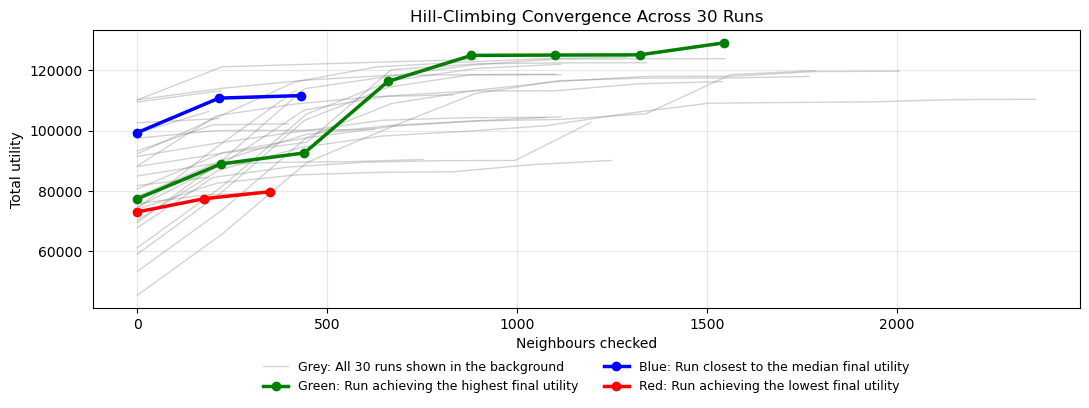

In [18]:
finals = np.array([run["final_utility"] for run in hill_climb_runs])
best = int(np.argmax(finals))
worst = int(np.argmin(finals))
median = int(np.argmin(np.abs(finals - np.median(finals))))

fig, ax = plt.subplots(figsize=(11, 5.5))

for run_index, run in enumerate(hill_climb_runs):
    history, checked = run["utility_history"], run["checked_history"]
    label = "Grey: All 30 runs shown in the background" if run_index == 0 else "_nolegend_"
    ax.plot(checked, history, color="grey", alpha=0.35, linewidth=1, label=label)

highlights = [
    (best, "Green: Run achieving the highest final utility", "green"),
    (median, "Blue: Run closest to the median final utility", "blue"),
    (worst, "Red: Run achieving the lowest final utility", "red"),
]
for index, label, color in highlights:
    history, checked = hill_climb_runs[index]["utility_history"], hill_climb_runs[index]["checked_history"]
    ax.plot(checked, history, marker="o", color=color, linewidth=2.5, label=label, zorder=3)

ax.set_xlabel("Neighbours checked")
ax.set_ylabel("Total utility")
ax.set_title("Hill-Climbing Convergence Across 30 Runs")
ax.grid(alpha=0.3)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False, fontsize=9)
fig.tight_layout(rect=(0, 0.20, 1, 1))
plt.show()

Across the 30 runs, utility generally rises as the hill climber accepts improvements, but final scores vary with the starting selection. The horizontal axis shows the cumulative number of neighbours checked, and the vertical axis shows total utility; each marker on a highlighted run is an accepted move, so the gap between markers shows what each improvement cost. Grey lines show all runs; green, blue, and red highlight the highest, median-nearest, and lowest final utilities.

**3.2.7 Operator Contribution**

In [19]:
# Count which operator produced each accepted improvement
swap_moves = 0
bit_flips = 0

for run in hill_climb_runs:
    history = run["solution_history"]

    for before, after in zip(history[:-1], history[1:]):
        changed = np.count_nonzero(before != after)

        if changed == 2:       # One selected and one unselected model exchanged
            swap_moves += 1
        elif changed == 1:     # One model added or removed
            bit_flips += 1
        else:
            raise AssertionError("Unexpected move in the search history")

total_moves = swap_moves + bit_flips
assert total_moves == sum(run["accepted_moves"] for run in hill_climb_runs)

print(f"Accepted swaps:     {swap_moves} ({100 * swap_moves / total_moves:.2f}%)")
print(f"Accepted bit flips: {bit_flips} ({100 * bit_flips / total_moves:.2f}%)")
print(f"Total improvements: {total_moves}")


Accepted swaps:     123 (91.11%)
Accepted bit flips: 12 (8.89%)
Total improvements: 135


Across the 30 runs, the hill climber accepted 135 improvements: 123 swaps (91.11%) and 12 bit flips (8.89%). The shares are calculated as follows:

$$
\begin{aligned}
\text{Swap share} &= \frac{123}{135} \times 100 = 91.11\%, \\
\text{Bit-flip share} &= \frac{12}{135} \times 100 = 8.89\%.
\end{aligned}
$$

These percentages count accepted moves, not the utility gained by each operator, and swaps examine more candidates than bit flips. Most accepted improvements were swaps, which supports including replacements when capacity limits restrict additions.

**3.2.8 Optimality Gap**

To measure how far the local optima fall short, I compute the exact optimum of Instance 1 with a dynamic program. It fills a $501 \times 501$ table with the best utility for every pair of capacity values, adding one model at a time. I use it only as a reference for the hill climber, not as a search method. It works because Instance 1 has two small integer capacities.

**Example: three models and two capacities of 3**

| Model | Resource 1 | Resource 2 | Utility |
|:---|---:|---:|---:|
| A | 2 | 1 | 8 |
| B | 1 | 2 | 7 |
| C | 3 | 3 | 12 |

If the random start adds C first, the hill climber stops at 12: removing C gives 0, adding A or B breaks both capacities, and swapping C for A or B gives 8 or 7. The optimum, A and B together, earns 15 but needs three changes at once. The dynamic program, used below for Instance 1, finds it directly. Each cell holds the best utility for that budget:

| Resource 1 \ Resource 2 | 0 | 1 | 2 | 3 |
|:---:|:---:|:---:|:---:|:---:|
| **0** | 0 | 0 | 0 | 0 |
| **1** | 0 | 0 | 7 | 7 |
| **2** | 0 | 8 | 8 | 8 |
| **3** | 0 | 8 | 8 | **15** |

The gap compares the utility found, $f$, with the optimum, $f^{*}$:

$$
\text{Gap} = \frac{f^{*} - f}{f^{*}} \times 100 = \frac{15 - 12}{15} \times 100 = 20\%.
$$

In [20]:
def knapsack_optimum(utilities, demands, capacities):
    """Exact optimum for two integer capacities by dynamic programming (reference only)."""
    table = np.zeros((int(capacities[0]) + 1, int(capacities[1]) + 1))
    for j in range(len(utilities)):
        r1, r2 = int(demands[0, j]), int(demands[1, j])
        with_model = np.full_like(table, -np.inf)
        with_model[r1:, r2:] = table[:table.shape[0] - r1, :table.shape[1] - r2] + utilities[j]
        table = np.maximum(table, with_model)
    return float(table[-1, -1])


assert len(b1) == 2 and np.all(R1 == np.round(R1)) and np.all(b1 == np.round(b1))
optimum_1 = knapsack_optimum(p1, R1, b1)
gaps = 100 * (optimum_1 - final_utilities) / optimum_1

print(f"Exact optimum (Instance 1): {optimum_1:,.0f}")
print(f"Runs reaching the optimum:  {np.sum(final_utilities == optimum_1)} / {N_RUNS}")
print(f"Best-run gap:  {gaps.min():.2f}%")
print(f"Median gap:    {np.median(gaps):.2f}%")
print(f"Mean gap:      {gaps.mean():.2f}%")
print(f"Worst-run gap: {gaps.max():.2f}%")

Exact optimum (Instance 1): 130,883
Runs reaching the optimum:  0 / 30
Best-run gap:  1.30%
Median gap:    14.59%
Mean gap:      16.73%
Worst-run gap: 39.05%


No run reaches the optimum of 130,883. The best run stops 1.30% short, the median gap is 14.59%, and the worst run is 39.05% below the optimum. Each run climbs from one random start and stops at the first local optimum it reaches in the flip-and-swap neighbourhood, so its result depends heavily on where it starts. More restarts would raise the chance that at least one run starts close enough to climb to the optimum, but they cannot guarantee it, and each restart costs another full climb. A population method spreads the search across many selections at once, which motivates the approach in Part 2.

### 3.3 Part 2: Advanced Population-Based Metaheuristic

Instance 2 has a much larger search space, with 90 binary model decisions and five resource constraints. The assignment gives the number of possible selections as follows:

$$
2^n = 2^{90} \approx 1.23 \times 10^{27}.
$$

That is about 1.23 octillion possible binary combinations. For this section, I use a variant of the genetic algorithm called a Diversity-Preserving Steady-State Genetic Algorithm (DP-SSGA). In practice, an engineer may want to choose among several good configurations, so I want separate niches to survive in the final population. SSGA is already exploitative itself [1]: it replaces the weakest population member, so if one elite region takes over, the population may fill with very similar selections and lose alternatives. To counter this, I replace that rule with Hamming-distance crowding: each child competes with its closest match among the 49 non-elite configurations and replaces it only if its utility is higher. I record diversity throughout the run to see how the population changes.

**3.3.1 Diversity-Preserving Steady-State Genetic Algorithm**

```mermaid
flowchart TD
    A["50 feasible 90-bit configurations"] --> A1["Evaluate initial population (50 fitness evaluations)"]
    A1 --> B["Binary tournament parent selection (t = 2)"]
    B --> C["Uniform crossover (0.8) and bit-flip mutation (1/90)"]
    C --> D["Closed greedy drop-add constraint repair"]
    D --> E["Evaluate repaired offspring utility"]
    E --> F["Hamming-distance crowding (protect global best)"]
    F --> G{"20,000 evaluations reached?"}
    G -- "No: create one offspring" --> B
    G -- "Yes" --> H["Return best feasible configuration"]
```


The operators are separate functions, so I can test each one on its own and reuse them in Part 3.

**3.3.2 Initial Population**

In [21]:
GA_POP_SIZE = 50
GA_EVALUATION_BUDGET = 20_000
GA_CROSSOVER_RATE = 0.8
GA_MUTATION_RATE = 1 / n2

I start the GA with `GA_POP_SIZE = 50` chromosomes so there are different model combinations to work with. A much smaller population could become similar after a few replacements, leaving crossover little variety to mix. A very large one would provide more starting choices, but scoring them would use more of the fixed `GA_EVALUATION_BUDGET = 20_000`, and Hamming-distance crowding would have more chromosomes to compare for every child. I set `GA_CROSSOVER_RATE = 0.8` to mix parent decisions often and `GA_MUTATION_RATE = 1/90` so a 90-bit child has about one flipped decision on average. At a 50% mutation rate, around 45 decisions would flip per child, breaking many inherited combinations and increasing repair work. With mutation at 0%, crossover and repair would carry the search, giving it fewer ways to explore new combinations.

In [22]:
def initial_population(utilities, demands, capacities, size):
    return np.array([random_feasible_start(utilities, demands, capacities) for _ in range(size)])

`initial_population()` builds each chromosome with `random_feasible_start()` from Part 1. Each chromosome starts with all models excluded; the function visits the models in a new random order and adds one only when all five capacities remain satisfied.

In [23]:
initial_ga_population = initial_population(p2, R2, b2, GA_POP_SIZE)
resource_usage = initial_ga_population @ R2.T
feasible_rows = np.all(resource_usage <= b2 + FEASIBILITY_TOL, axis=1)

assert initial_ga_population.shape == (GA_POP_SIZE, n2)
assert np.all((initial_ga_population == 0) | (initial_ga_population == 1))
assert feasible_rows.all()

print("Population shape:", initial_ga_population.shape)
print("Distinct configurations:", len(np.unique(initial_ga_population, axis=0)))
print("Feasible configurations:", feasible_rows.sum(), "/", GA_POP_SIZE)
print("First configuration demand:", resource_usage[0].astype(int))
print("Resource capacity limits:", b2.astype(int))

Population shape: (50, 90)
Distinct configurations: 50
Feasible configurations: 50 / 50
First configuration demand: [1328 1100 1910 1676 1571]
Resource capacity limits: [2100 1100 3300 3700 3600]


The output shows 50 distinct, feasible 90-bit configurations. `initial_ga_population @ R2.T` gives a 50-by-5 matrix of resource use, with one row per configuration and one column per resource. The assertions check the population shape, binary decisions and all five capacity limits.

**3.3.3 Fitness Evaluation**

In [24]:
def fitness(solution, utilities):
    return float(utilities @ solution)

Following Luke [1], fitness assessment provides the basis for comparing candidate solutions during evolutionary search. I define `fitness()` once so the same utility objective (3) is used when scoring one individual and when evaluating the population.

In [25]:
# Vectorised fitness evaluation: one dot product per initial individual
initial_fitness = initial_ga_population @ p2
print("Mean initial fitness:", round(float(initial_fitness.mean()), 2))
print("Best initial fitness:", float(initial_fitness.max()))
print("Best initial model count:", int(initial_ga_population[np.argmax(initial_fitness)].sum()))

Mean initial fitness: 6018.02
Best initial fitness: 8160.0
Best initial model count: 48


`initial_ga_population @ p2` scores the 50 initial configurations in one operation. Their mean and best utilities show variation in starting quality. The GA stores these scores and updates one only when `hamming_crowding()` accepts a replacement, avoiding a full population re-evaluation.

**3.3.4 Parent Selection**

In [26]:
def tournament_parent(population, scores):
    indices = np.random.randint(len(population), size=2)
    return population[indices[np.argmax(scores[indices])]].copy()

Next, I use binary tournament selection ($t=2$) to choose parents. `tournament_parent()` samples two population members, and the one with higher utility becomes a parent. This favours promising solutions while allowing weaker individuals to be selected occasionally, reducing selection pressure compared with larger tournaments. Each tournament reads two cached scores, so selection adds almost no cost.

**3.3.5 Variation: Uniform Crossover and Bit-Flip Mutation**

In [27]:
def uniform_crossover(parent_a, parent_b, probability=0.8):
    if np.random.random() >= probability:
        return parent_a.copy()
    mask = np.random.random(len(parent_a)) < 0.5
    return np.where(mask, parent_a, parent_b).astype(np.int8)

In [28]:
def bit_flip_mutation(child, probability):
    mutated = child.copy()
    mask = np.random.random(len(child)) < probability
    mutated[mask] = 1 - mutated[mask]
    return mutated

I use uniform crossover with probability 0.8 because model positions in the data file do not represent neighbouring physical components: taking genes from either parent independently avoids relying on a meaningful one-point cut. Bit-flip mutation changes each decision with probability $1/90$, giving one flip per child on average, not exactly one. It introduces choices absent from one or both parents. Both operators may violate capacity limits; neither guarantees improvement.

**For example: sample of six AI model decisions**

**Step 1: Uniform crossover.** Suppose the crossover draw is $0.62 < 0.80$, so crossover takes place. A separate 50/50 choice at each position decides which parent supplies that model decision.

| Selection | Model 1 | Model 2 | Model 3 | Model 4 | Model 5 | Model 6 |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| Parent A | 1 | 1 | 0 | 0 | 1 | 0 |
| Parent B | 0 | 0 | 1 | 1 | 0 | 1 |
| Parent chosen | A | B | A | B | A | B |
| Child after crossover | **1** | **0** | **0** | **1** | **1** | **1** |

**Step 2: Bit-flip mutation.** Each of the 90 model decisions has a $1/90$ chance of flipping. In this example, Model 4 changes from `1` (deploy) to `0` (skip). The resulting child is `[1, 0, 0, 0, 1, 1]` for these six models:

| Selection | Model 1 | Model 2 | Model 3 | Model 4 | Model 5 | Model 6 |
|:---|:---:|:---:|:---:|:---:|:---:|:---:|
| Before mutation | 1 | 0 | 0 | **1** | 1 | 1 |
| After mutation | 1 | 0 | 0 | **0** | 1 | 1 |

In [29]:
parent_a = tournament_parent(initial_ga_population, initial_fitness)
parent_b = tournament_parent(initial_ga_population, initial_fitness)
child = uniform_crossover(parent_a, parent_b, GA_CROSSOVER_RATE)
child = bit_flip_mutation(child, GA_MUTATION_RATE)
assert len(child) == n2
assert np.all((child == 0) | (child == 1))
print("After crossover and mutation: ", child)
print("Variation generated a valid 90-bit chromosome:", child.shape)

After crossover and mutation:  [1 0 0 0 1 0 1 0 0 1 0 0 1 0 1 0 0 1 0 0 0 0 1 1 1 1 1 0 0 0 1 1 0 1 0 0 1
 0 1 0 0 1 0 1 0 0 0 0 0 1 1 0 0 1 0 1 1 1 0 1 0 0 1 1 0 1 0 1 0 1 0 0 0 1
 0 0 1 0 1 1 1 0 0 0 1 0 0 0 0 1]
Variation generated a valid 90-bit chromosome: (90,)


This check confirms that selection, crossover and mutation produce a 90-bit binary chromosome in `child`. It does not test utility or feasibility; the repair step handles resource limits next.

**3.3.6 Constraint Handling: Closed Greedy Drop-Add Repair**

In [30]:
def efficiency_order(utilities, demands, capacities):
    density = utilities / np.maximum((demands / capacities[:, None]).sum(axis=0), 1e-12)
    return np.argsort(density), np.argsort(-density)

I rank models by utility per total capacity-normalised demand, $e_j=p_j/\sum_{i=1}^{m}(r_{i,j}/b_i)$. This drop-and-add design follows Chu and Beasley [2]. They weight each resource with dual values from a linear relaxation, whereas I divide each demand by its capacity, which makes resource use comparable across differently sized limits. Because every child is repaired with the same ranking, repair pushes children towards the same models. `efficiency_order()` calculates the ranking once before the search loop, avoiding repeated ranking work during repair.

In [31]:
def greedy_drop_add(solution, demands, capacities, drop_order, add_order):
    repaired = solution.copy()
    usage = demands @ repaired
    removed = added = 0
    for j in drop_order:
        if np.all(usage <= capacities + FEASIBILITY_TOL):
            break
        if repaired[j]:
            repaired[j] = 0
            usage -= demands[:, j]
            removed += 1
    for j in add_order:
        if not repaired[j] and np.all(usage + demands[:, j] <= capacities + FEASIBILITY_TOL):
            repaired[j] = 1
            usage += demands[:, j]
            added += 1
    return repaired, removed, added

Luke [1, Sec. 8.1] explains that crossover and mutation can produce offspring that violate hard resource constraints due to over-accumulation (selecting too many models) and overflow (total resource demand exceeding capacity). I therefore use `greedy_drop_add()` to make each child feasible before scoring it. The drop phase removes selected models from lowest to highest efficiency, freeing capacity at the least utility cost, until all constraints are met (4). The add phase then tries excluded models from highest to lowest efficiency and adds each one that fits, recovering utility; it also runs on already feasible offspring.

A fixed ranking can remove a useful model, so this rule guarantees feasibility rather than the best possible utility. Repair ensures that only feasible configurations are evaluated, replacing penalty-weight tuning. The trade-off is extra work per child: in Part 3, repair drops 1.2–1.9 models per child on average (Section 3.4.9).

In [32]:
drop_order, add_order = efficiency_order(p2, R2, b2)

# Stress test: selecting every model breaches the hardware limits.
infeasible_test = np.ones(n2, dtype=np.int8)
repaired_test, removed, added = greedy_drop_add(infeasible_test, R2, b2, drop_order, add_order)
repaired_usage = R2 @ repaired_test
assert np.all(repaired_usage <= b2 + FEASIBILITY_TOL)

# Closure: no excluded model can now be added on its own.
for j in np.flatnonzero(repaired_test == 0):
    assert np.any(repaired_usage + R2[:, j] > b2 + FEASIBILITY_TOL)

print("Models removed:", removed, "| Models added:", added)
print("Repaired demand:", repaired_usage.astype(int))
print("Capacity limits:", b2.astype(int))
print("Feasible and single-add maximal: True")

Models removed: 48 | Models added: 1
Repaired demand: [1482 1099 1743 1601 2197]
Capacity limits: [2100 1100 3300 3700 3600]
Feasible and single-add maximal: True


I test `greedy_drop_add()` on `np.ones(n2, dtype=np.int8)`, which selects every model and exceeds the capacities. Repair removes 48 models and adds 1, leaving 43 models selected (90 − 48 + 1 = 43); the assertions check feasibility and confirm that no excluded model can be added directly. In the full demonstration run, 9,753 of the 19,950 offspring (48.9%) were infeasible before repair, showing how often the operator is needed.

**3.3.7 Survival: Hamming-Distance Crowding and Elite Shielding**

In [33]:
def hamming_crowding(population, scores, child, child_score, return_removed=False):
    # Reject duplicate chromosomes
    if np.any(np.all(population == child, axis=1)):
        if return_removed:
            return False, None
        return False
    
    # Protect the best individual
    elite_index = int(np.argmax(scores))
    eligible_indices = np.arange(len(population))
    eligible_indices = eligible_indices[eligible_indices != elite_index]

    # Find the most similar individual using Hamming distance
    distances = np.count_nonzero(population[eligible_indices] != child, axis=1)
    closest_indices = eligible_indices[distances == distances.min()]
    nearest = int(np.random.choice(closest_indices))

    # Reject offspring that do not improve their closest neighbour
    if child_score <= scores[nearest]:
        if return_removed:
            return False, None
        return False
    
    # Replace the neighbour with the better offspring
    removed = population[nearest].copy()
    population[nearest] = child
    scores[nearest] = child_score

    if return_removed:
        return True, removed
    return True

Mengshoel and Goldberg [3] describe crowding as competition between similar individuals. I use Hamming-distance crowding to encourage competition between structurally similar configurations rather than automatically replacing the weakest individual. Hamming distance is $H(x,y)=\sum_j|x_j-y_j|$. `hamming_crowding()` rejects exact duplicates and protects the highest-scoring chromosome.

By replacing the closest non-elite individual only when the offspring has higher utility, I aim to preserve alternative configurations while improving solution quality. This uses the similarity-based idea in [3] without a sampled window.

In [34]:
def population_diversity(population):
    counts = population.sum(axis=0)
    n = len(population)
    return float(np.sum(counts * (n - counts)) / (n * (n - 1) / 2))

`population_diversity()` calculates mean pairwise Hamming distance from per-gene selection counts. For each gene, `counts * (n - counts)` gives the number of population pairs that differ there. Summing across genes and dividing by the number of pairs avoids explicit pairwise comparisons.

In [35]:
# Test elite shielding and duplicate rejection
# Utilities: 14 (elite), 10, and 3.
toy_population = np.array([[1, 1, 0, 0], [1, 0, 0, 0], [0, 0, 1, 0]], dtype=np.int8)
toy_utilities = np.array([10, 4, 3, 1])
toy_scores = toy_population @ toy_utilities
original_elite = toy_population[0].copy()

# The new child has utility 17 and is closest to the protected elite.
toy_child = np.array([1, 1, 1, 0], dtype=np.int8)
child_score = fitness(toy_child, toy_utilities)
accepted = hamming_crowding(toy_population, toy_scores, toy_child, child_score)

assert accepted
assert np.array_equal(toy_population[0], original_elite)

# A chromosome already in the population must be rejected.
duplicate_accepted = hamming_crowding(
    toy_population, toy_scores, original_elite, fitness(original_elite, toy_utilities)
)
assert not duplicate_accepted

print("Better child accepted:", accepted)
print("Original elite protected:", np.array_equal(toy_population[0], original_elite))
print("Duplicate rejected:", not duplicate_accepted)

Better child accepted: True
Original elite protected: True
Duplicate rejected: True


This is a focused test of two replacement rules rather than overall search quality. With a fixed population and child, `hamming_crowding()` accepts a better child without removing the protected best and rejects an identical copy.

**3.3.8 Complete DP-SSGA Algorithm**

In [36]:
def create_offspring(population, scores, utilities, demands, capacities,
                     drop_order, add_order, crossover_rate, mutation_rate):
    """Select parents, apply variation, repair, and evaluate one child."""
    parent_a = tournament_parent(population, scores)
    parent_b = tournament_parent(population, scores)

    child = uniform_crossover(parent_a, parent_b, crossover_rate)
    child = bit_flip_mutation(child, mutation_rate)
    infeasible = bool(np.any(demands @ child > capacities + FEASIBILITY_TOL))
    child, removed, added = greedy_drop_add(child, demands, capacities, drop_order, add_order)

    return child, fitness(child, utilities), infeasible, removed, added

`create_offspring()` chains the operators from Sections 3.3.3–3.3.6 for one child: it selects two parents, applies crossover and mutation, records whether the child breaks a capacity, then repairs and scores it. Part 3 reuses this function, so both GAs build children in exactly the same way.

In [37]:
def run_dp_ssga(utilities, demands, capacities, population_size=50, evaluation_budget=20000,
                crossover_rate=0.8, mutation_rate=None, record_every=250, record_trajectory=False):
    if evaluation_budget < population_size or population_size < 2:
        raise ValueError("Evaluation budget must be at least the population size (>=2).")
    if mutation_rate is None:
        mutation_rate = 1 / len(utilities)

    # Before A: efficiency_order() (3.3.6) fixes the drop-add repair order.
    drop_order, add_order = efficiency_order(utilities, demands, capacities)
    # A (3.3.2): initial_population() builds feasible starting configurations.
    population = initial_population(utilities, demands, capacities, population_size)
    starting_population = population.copy()
    # A1: score the starts; population_size evaluations count toward the budget.
    scores = population @ utilities
    evaluations = population_size
    best_index = int(np.argmax(scores))
    best_solution = population[best_index].copy()
    best_score = float(scores[best_index])
    history_evals = [evaluations]
    history_best = [best_score]
    history_mean = [float(scores.mean())] if record_trajectory else None
    history_diversity = [population_diversity(population)]
    # Store full trajectories only when the plots need them.
    offspring_history = (
        np.empty((evaluation_budget - population_size, len(utilities)), dtype=np.int8)
        if record_trajectory else None
    )
    best_solution_path = [best_solution.copy()] if record_trajectory else None
    replacement_links = [] if record_trajectory else None
    replaced_count = repaired_count = drop_count = add_count = 0

    # G: repeat nodes B-F until the evaluation budget is reached.
    while evaluations < evaluation_budget:
        # B-E (3.3.3-3.3.6): create_offspring() selects parents, varies, repairs and scores one child.
        child, child_score, infeasible, removed, added = create_offspring(
            population, scores, utilities, demands, capacities,
            drop_order, add_order, crossover_rate, mutation_rate
        )
        repaired_count += infeasible
        drop_count += removed
        add_count += added
        evaluations += 1
        # F (3.3.7): hamming_crowding() decides whether the child replaces a non-elite.
        if record_trajectory:
            offspring_history[evaluations - population_size - 1] = child
            replaced, removed_solution = hamming_crowding(population, scores, child, child_score, return_removed=True)
            if replaced:
                replacement_links.append((removed_solution, child.copy()))
        else:
            replaced = hamming_crowding(population, scores, child, child_score)
        if replaced:
            replaced_count += 1
        # After F: record a new best only when crowding admits the child.
        if child_score > best_score:
            assert replaced, "New global best must enter the population."
            best_score = child_score
            best_solution = child.copy()
            if record_trajectory:
                best_solution_path.append(best_solution.copy())
        # Sample population_diversity() (3.3.7) for the search plots.
        if evaluations % record_every == 0 or evaluations == evaluation_budget:
            history_evals.append(evaluations)
            history_best.append(best_score)
            if record_trajectory:
                history_mean.append(float(scores.mean()))
            history_diversity.append(population_diversity(population))

    # H: verify feasibility and return the best feasible configuration.
    assert np.all(demands @ population.T <= capacities[:, None] + FEASIBILITY_TOL)
    assert np.array_equal(population[np.argmax(scores)], best_solution)
    assert best_score == float(scores.max())
    return {
        "solution": best_solution,
        "utility": best_score,
        "population": population,
        "starting_population": starting_population,
        "scores": scores,
        "evaluations": evaluations,
        "replacements": replaced_count,
        "infeasible_offspring": repaired_count,
        "dropped_models": drop_count,
        "added_models": add_count,
        "evaluation_history": np.array(history_evals),
        "utility_history": np.array(history_best),
        "mean_population_utility_history": np.array(history_mean) if record_trajectory else None,
        "diversity_history": np.array(history_diversity),
        "offspring_history": offspring_history,
        "best_solution_path": np.array(best_solution_path) if record_trajectory else None,
        "replacement_links": replacement_links,
    }

`run_dp_ssga()` combines the separate initialisation, selection, variation, repair and replacement functions. It evaluates the initial population, then one offspring at a time until the budget is reached. For the demonstration run, I also record mean utility, offspring, global-best solutions and accepted replacements for the plots.

In [38]:
start_time = time.perf_counter()
demo_ga_result = run_dp_ssga(
    p2, R2, b2,
    population_size=GA_POP_SIZE,
    evaluation_budget=GA_EVALUATION_BUDGET,
    crossover_rate=GA_CROSSOVER_RATE,
    mutation_rate=GA_MUTATION_RATE,
    record_trajectory=True
)
ga_runtime = time.perf_counter() - start_time

assert demo_ga_result["evaluations"] == GA_EVALUATION_BUDGET
assert np.all(R2 @ demo_ga_result["solution"] <= b2 + FEASIBILITY_TOL)
assert np.all((demo_ga_result["solution"] == 0) | (demo_ga_result["solution"] == 1))
assert np.all(np.diff(demo_ga_result["utility_history"]) >= 0)

print("Best feasible utility:", f'{demo_ga_result["utility"]:,.0f}')
print("Selected models:", int(demo_ga_result["solution"].sum()))
print("Resource use:", (R2 @ demo_ga_result["solution"]).astype(int))
print("Capacity limits:", b2.astype(int))
print("Fitness evaluations:", demo_ga_result["evaluations"])
print("Accepted replacements:", demo_ga_result["replacements"])
print("Offspring initially infeasible:", demo_ga_result["infeasible_offspring"])
print("Models dropped / added:", demo_ga_result["dropped_models"], "/", demo_ga_result["added_models"])
print("Runtime (seconds):", round(ga_runtime, 2))

Best feasible utility: 11,191
Selected models: 51
Resource use: [1777 1100 2259 2232 2418]
Capacity limits: [2100 1100 3300 3700 3600]
Fitness evaluations: 20000
Accepted replacements: 667
Offspring initially infeasible: 9753
Models dropped / added: 38275 / 30857
Runtime (seconds): 6.55


The demonstration run reaches utility 11,191 with 51 selected models after 20,000 evaluations. It accepts 667 replacements, and Resource 2 reaches its 1,100-unit limit. I use the next figures to examine how utility and diversity changed during that search.

**Design contribution.** Each component comes from the literature, but I combine them for this problem. About half of all children break a capacity limit (Section 3.3.6), so repair runs on every child, and its add phase also fills spare capacity in children that are already feasible. Because the same efficiency ranking repairs every child, repair pulls the population towards the same models. I use Hamming crowding to counter that pull, since each child competes only with its nearest neighbour, while duplicate rejection and elite shielding stop crowding from storing copies or losing the best selection.

**3.3.9 Search Behaviour and Population Diversity**

I compare the best-so-far utility with the current population's mean utility and track mean pairwise Hamming distance for the single demonstration run.

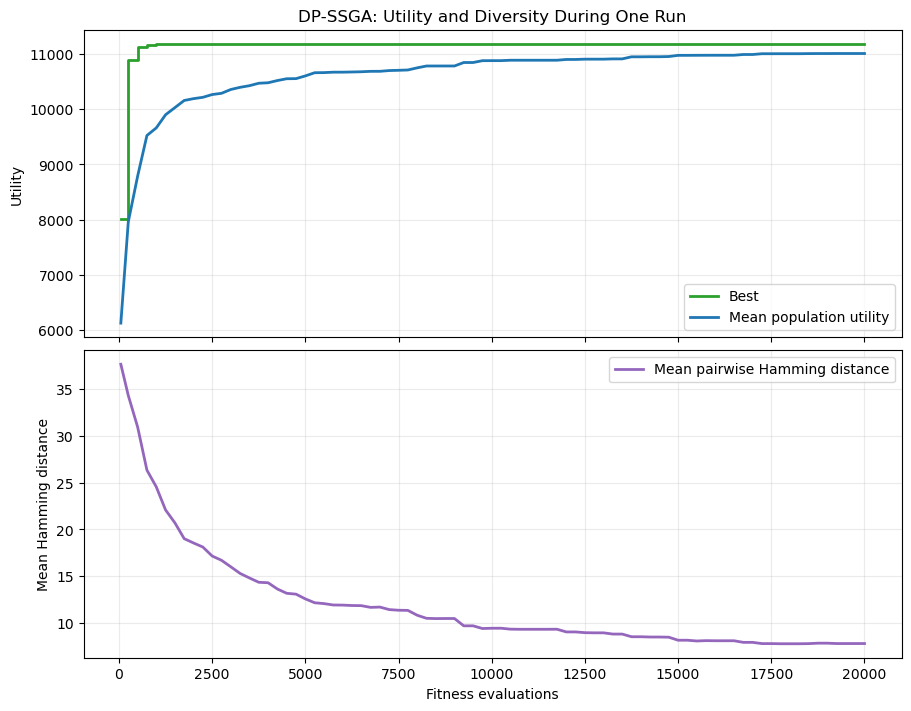

Initial population (50 evaluations):
  Best utility: 8,017
  Mean utility: 6,124
Final population (20,000 evaluations):
  Best utility: 11,191
  Mean utility: 11,012


In [39]:
evals = demo_ga_result["evaluation_history"]
best_history = demo_ga_result["utility_history"]
mean_history = demo_ga_result["mean_population_utility_history"]
diversity_history = demo_ga_result["diversity_history"]

fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True, constrained_layout=True)

axes[0].step(evals, best_history, where="post", color="tab:green", linewidth=2, label="Best")
axes[0].plot(evals, mean_history, color="tab:blue", linewidth=2, label="Mean population utility")
axes[0].set_ylabel("Utility")
axes[0].set_title("DP-SSGA: Utility and Diversity During One Run")
axes[0].legend()
axes[0].grid(alpha=0.25)

axes[1].plot(evals, diversity_history, color="tab:purple", linewidth=2, label="Mean pairwise Hamming distance")
axes[1].set_ylabel("Mean Hamming distance")
axes[1].set_xlabel("Fitness evaluations")
axes[1].legend()
axes[1].grid(alpha=0.25)

plt.show()
print(f"Initial population ({evals[0]:,} evaluations):")
print(f"  Best utility: {best_history[0]:,.0f}")
print(f"  Mean utility: {mean_history[0]:,.0f}")
print(f"Final population ({evals[-1]:,} evaluations):")
print(f"  Best utility: {best_history[-1]:,.0f}")
print(f"  Mean utility: {mean_history[-1]:,.0f}")


By the 1,500-evaluation checkpoint, the best recorded utility had risen from 8,017 to 11,191. The population mean rose more gradually, from about 6,124 to 11,012 by the end of the run, narrowing the gap between the two lines. This fits the steady-state design: one offspring is evaluated at a time, while elite shielding keeps the best selection in the population until a better one is found.

Mean pairwise Hamming distance fell from 37.68 to 7.79 over the same run. The population gained utility as its model selections became more alike.

I project the initial population and feasible offspring into two PCA axes to see where new configurations appear during the search.

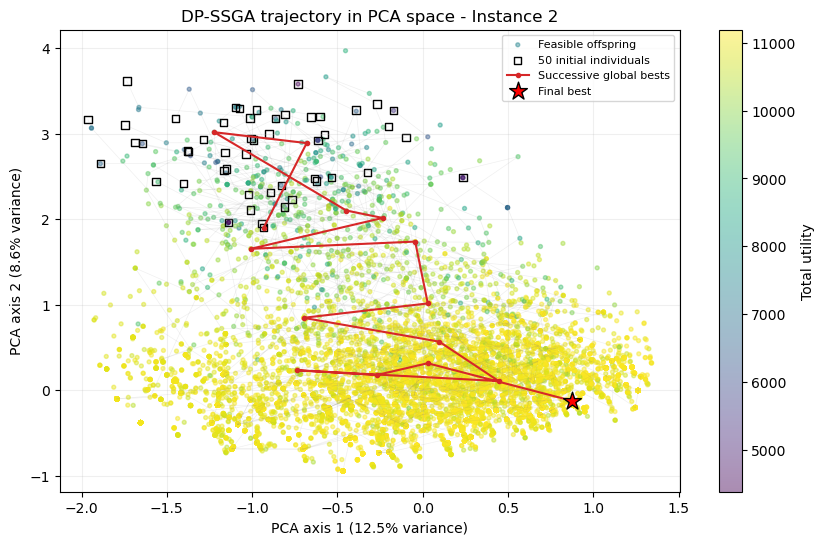

PCA variance explained: axis 1 12.49%, axis 2 8.60%, combined 21.08%


In [ ]:
initial = demo_ga_result["starting_population"]
offspring = demo_ga_result["offspring_history"]
configurations = np.vstack((initial, offspring))
centre = configurations.mean(axis=0)
_, singular_values, directions = np.linalg.svd(configurations - centre, full_matrices=False)
variance_pct = 100 * singular_values ** 2 / np.sum(singular_values ** 2)

def project(x):
    return (np.asarray(x) - centre) @ directions[:2].T

best_xy = project(demo_ga_result["best_solution_path"])
links_xy = project(demo_ga_result["replacement_links"])  # (replacements, old/new, axis)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(links_xy[:, :, 0].T, links_xy[:, :, 1].T, color="grey", alpha=0.12, linewidth=0.5)
points = ax.scatter(*project(offspring).T, c=offspring @ p2, cmap="viridis", s=8, alpha=0.45,label="Feasible offspring")
ax.scatter(*project(initial).T, marker="s", facecolors="none", edgecolors="black", s=28,label=f"{len(initial)} initial individuals")
ax.plot(*best_xy.T, color="tab:red", marker="o", markersize=3, linewidth=1.5, label="Successive global bests")
ax.scatter(*best_xy[-1], marker="*", color="red", edgecolors="black", s=180, label="Final best", zorder=4)
fig.colorbar(points, ax=ax, label="Total utility")
ax.set(title="DP-SSGA trajectory in PCA space - Instance 2",xlabel=f"PCA axis 1 ({variance_pct[0]:.1f}% variance)",ylabel=f"PCA axis 2 ({variance_pct[1]:.1f}% variance)")
ax.legend(fontsize=8)
ax.grid(alpha=0.2)
plt.show()
print(f"PCA variance explained: axis 1 {variance_pct[0]:.2f}%, axis 2 {variance_pct[1]:.2f}%, "f"combined {variance_pct[:2].sum():.2f}%")

The two PCA axes capture 21.08% of the variation. The search leaves the starting region at the top and settles in one broad band of high-utility configurations, not in several separate clusters. In this view, crowding keeps many different good selections spread along one region rather than preserving distinct niches. Because the plot shows every offspring rather than only the retained population, I use the Hamming curve above to judge how the population's diversity changed.

**3.3.10 Summary and Limitations**

The plots show that utility rose early while population diversity fell during the run. The PCA view suggests that crowding kept many different good selections but not distinct niches, so the motivation in Section 3.3 is only partly met.

However, the fixed greedy repair ranking may favour similar resource-efficient configurations, potentially restricting exploration. Hamming crowding also requires additional similarity comparisons, but its benefit over conventional fitness-based replacement and its diversity-preserving effectiveness have not yet been established within this experiment. Furthermore, only one population size and set of variation probabilities were tested. These limitations motivate a controlled comparison of DP-SSGA with a standard Generational GA under equal fitness-evaluation budgets in Part 3.

### 3.4 Part 3: Empirical Study and Hypothesis Testing

**3.4.1 Research Question, Motivation and Hypotheses**

Following the findings and limitations of my DP-SSGA, I raise the following research question:

**Research question:** Does diversity-preserving steady-state replacement improve solution quality and diversity on Instance 2 (90 models and five constraints) compared with generational replacement, and at what computational cost?

To answer this question, I compare my DP-SSGA with a standard Generational Genetic Algorithm (Generational GA). Both share the same initialisation, binary tournament selection, uniform crossover, bit-flip mutation, and greedy drop-add repair. They differ in their replacement mechanism: the Generational GA replaces the population after each batch of 50 children, while DP-SSGA replaces one chromosome at a time through Hamming-distance crowding.

On the basis of this difference, I formulate three hypotheses:

**H1 — Anytime Solution Quality**

I expect DP-SSGA to reach higher utility over the search as a whole. Crowding should stop one region from filling the population, so the search is less likely to stall below the best configuration, even if it gains utility more slowly at first. I measure this with anytime utility, the average best-so-far utility across all 20,000 evaluations (Section 3.4.6).

- **H₀:** DP-SSGA does not achieve higher anytime utility than the Generational GA.
- **H₁:** DP-SSGA achieves higher anytime utility than the Generational GA.

**H2 — Population Diversity**

I expect DP-SSGA to retain more structural diversity because each child competes only with its most similar chromosome. Generational survival keeps the 49 best children of each batch, so near-copies of one strong selection can fill the population.

- **H₀:** DP-SSGA does not maintain greater diversity than the Generational GA.
- **H₁:** DP-SSGA maintains greater diversity than the Generational GA.

**H3 — Execution Time**

I expect DP-SSGA to take longer. Every DP-SSGA child needs a duplicate check and a Hamming-distance comparison with the 49 non-elite chromosomes, about 4,410 bit comparisons, while the Generational GA sorts each batch of 50 children once. Hardware checks are outside the scope of this study.

- **H₀:** DP-SSGA is not slower than the Generational GA.
- **H₁:** DP-SSGA is slower than the Generational GA.

**3.4.2 Controlled Protocol and Algorithmic Variants**

| Setting | Generational GA | DP-SSGA |
|---|---|---|
| Initial population size | 50 | 50 |
| Population model | Generational: population replaced after each batch of 50 children | Steady-state: one child at a time |
| Parent choice | Binary tournament ($t=2$) | Same |
| Variation | Uniform crossover (0.8), bit flips ($1/90$) | Same |
| Repair | Greedy drop-add | Same |
| Survival | Batch selection: previous elite + best 49 offspring | Hamming crowding: replace nearest non-elite if improved |
| Budget | 20,000 fitness evaluations | Same |
| Trials | 30 matched seeds | Same |

I keep the population size, 20,000-evaluation budget, variation operators, and repair method the same for both variants, so any difference comes from the replacement mechanism. That mechanism has two parts: when parents are updated (after a batch or after each child) and which chromosome a child replaces (by truncation or its nearest neighbour). This study compares the two complete designs; it cannot separate the effect of these two parts.

In [41]:
import pandas as pd

PART3_SEEDS = range(200, 230)
PART3_VARIANTS = ("Generational GA", "DP-SSGA")
PART3_RECORD_EVERY = 250
PART3_CHECKPOINTS = np.r_[GA_POP_SIZE,np.arange(PART3_RECORD_EVERY, GA_EVALUATION_BUDGET + 1, PART3_RECORD_EVERY)]
PART3_REFERENCE_UTILITY = float(demo_ga_result["utility"])

print(f"Part 2 best observed utility (comparison reference): {PART3_REFERENCE_UTILITY:,.0f}")

Part 2 best observed utility (comparison reference): 11,191


`PART3_SEEDS` defines 30 reproducible runs, while `PART3_VARIANTS` identifies the algorithms being compared. `PART3_CHECKPOINTS` tracks convergence at fixed evaluation intervals, and `PART3_REFERENCE_UTILITY` provides the best observed utility from Part 2 as a performance benchmark.

**3.4.3 Shared Offspring Generation**

Both variants build each child with `create_offspring()` from Section 3.3.8, so the Generational GA uses exactly the same selection, crossover, mutation, and repair as DP-SSGA and records the same repair counts.

**3.4.4 Generational Survival**

In [42]:
def part3_generational_survival(population, scores, children, child_scores):
    """Keep the old elite and the best offspring for the next generation."""
    population_size = len(population)

    elite_index = int(np.argmax(scores))
    elite_solution = population[elite_index].copy()
    elite_score = float(scores[elite_index])

    offspring_order = np.argsort(-child_scores, kind="stable")
    survivor_indices = offspring_order[:population_size - 1]

    next_population = np.vstack((elite_solution[None, :], children[survivor_indices]))
    next_scores = np.r_[elite_score, child_scores[survivor_indices]]
    return next_population, next_scores

Because parents in the Generational GA remain fixed while a complete batch of offspring is produced, I declare a new function for the survival selection. The next generation keeps the best parent and the 49 best children.

**3.4.5 Complete Generational GA Algorithm**

In [43]:
def run_generational_ga(
    utilities, demands, capacities, population_size=50,
    evaluation_budget=20000, crossover_rate=0.8,
    mutation_rate=None, record_every=250,
):
    """Run the Generational GA with a fixed evaluation budget."""
    if population_size < 2 or evaluation_budget < population_size:
        raise ValueError("Invalid population size or evaluation budget")
    if (evaluation_budget - population_size) % population_size:
        raise ValueError("Generational GA needs complete offspring batches")
    if record_every <= 0:
        raise ValueError("Checkpoint spacing must be positive")
    if mutation_rate is None:
        mutation_rate = 1 / len(utilities)

    # Initialise and score a common-sized feasible population.
    drop_order, add_order = efficiency_order(utilities, demands, capacities)
    population = initial_population(utilities, demands, capacities, population_size)
    scores = population @ utilities
    evaluations = population_size

    best_index = int(np.argmax(scores))
    best_solution = population[best_index].copy()
    best_score = float(scores[best_index])

    evaluation_history = [evaluations]
    utility_history = [best_score]
    diversity_history = [population_diversity(population)]
    infeasible_count = drop_count = add_count = 0

    while evaluations < evaluation_budget:
        # Produce the entire generation from unchanged parents.
        children = np.empty_like(population)
        child_scores = np.empty(population_size, dtype=float)
        for index in range(population_size):
            children[index], child_scores[index], infeasible, removed, added = create_offspring(
                population, scores, utilities, demands, capacities,
                drop_order, add_order, crossover_rate, mutation_rate
            )
            infeasible_count += infeasible
            drop_count += removed
            add_count += added

        population, scores = part3_generational_survival(population, scores, children, child_scores)
        evaluations += population_size

        current_best_index = int(np.argmax(scores))
        if scores[current_best_index] > best_score:
            best_score = float(scores[current_best_index])
            best_solution = population[current_best_index].copy()

        if evaluations % record_every == 0 or evaluations == evaluation_budget:
            evaluation_history.append(evaluations)
            utility_history.append(best_score)
            diversity_history.append(population_diversity(population))

    assert evaluations == evaluation_budget
    assert np.all(demands @ population.T <= capacities[:, None] + FEASIBILITY_TOL)
    assert np.all(demands @ best_solution <= capacities + FEASIBILITY_TOL)
    assert best_score == float(scores.max())

    return {
        "solution": best_solution,
        "utility": best_score,
        "evaluations": evaluations,
        "evaluation_history": np.asarray(evaluation_history),
        "utility_history": np.asarray(utility_history),
        "diversity_history": np.asarray(diversity_history),
        "infeasible_offspring": infeasible_count,
        "dropped_models": drop_count,
        "added_models": add_count,
    }

Within the main while loop, the Generational GA produces a full batch of 50 offspring from unchanged parents and then updates the population through generational survival. It adds up the repair counts for every child, and it records the best-so-far utility and population diversity at the same evaluation checkpoints as DP-SSGA, ensuring a consistent comparison of convergence behaviour.

**3.4.6 Performance Metrics**

In [44]:
def part3_time_average(values, evaluation_points):
    """Compute an evaluation-weighted average using the trapezoidal rule."""
    interval_lengths = np.diff(evaluation_points)
    interval_means = (values[:-1] + values[1:]) / 2
    area = np.sum(interval_lengths * interval_means)
    total_interval = evaluation_points[-1] - evaluation_points[0]
    return float(area / total_interval)

`part3_time_average()` computes anytime utility: the area under the best-so-far curve (trapezoidal rule) divided by the evaluation span. A higher value means a variant reached good utility earlier and held it, which is the evidence for H1.

**3.4.7 Run Validation**

In [45]:
def part3_validate_result(result):
    """Check budget, checkpoint alignment, feasibility, and utility history."""
    solution = result["solution"]

    assert result["evaluations"] == GA_EVALUATION_BUDGET
    assert np.array_equal(result["evaluation_history"], PART3_CHECKPOINTS)
    assert np.all((solution == 0) | (solution == 1))
    assert np.all(R2 @ solution <= b2 + FEASIBILITY_TOL)
    assert np.all(np.diff(result["utility_history"]) >= 0)
    assert result["utility"] == float(p2 @ solution)

This function checks that each run follows the same evaluation budget and checkpoints, produces a feasible binary solution, and records non-decreasing best-so-far utility. This stops a broken run from entering the statistics.

**3.4.8 Matched-Seed Experiment**

In [46]:
def part3_run_experiments():
    """Run both GA variants across 30 matched seeds."""
    runs = {variant: [] for variant in PART3_VARIANTS}
    offspring = GA_EVALUATION_BUDGET - GA_POP_SIZE

    settings = {
        "population_size": GA_POP_SIZE,
        "evaluation_budget": GA_EVALUATION_BUDGET,
        "crossover_rate": GA_CROSSOVER_RATE,
        "mutation_rate": GA_MUTATION_RATE,
        "record_every": PART3_RECORD_EVERY,
    }

    for i, seed in enumerate(PART3_SEEDS):
        # Rotate execution order to reduce timing bias.
        shift = i % len(PART3_VARIANTS)
        order = PART3_VARIANTS[shift:] + PART3_VARIANTS[:shift]

        for variant in order:
            np.random.seed(seed)
            start_time = time.perf_counter()

            if variant == "DP-SSGA":
                result = run_dp_ssga(p2, R2, b2, **settings, record_trajectory=False)
            else:
                result = run_generational_ga(p2, R2, b2, **settings)

            runtime = time.perf_counter() - start_time
            part3_validate_result(result)

            history = result["evaluation_history"]

            runs[variant].append({
                "seed": seed,
                "final_utility": float(result["utility"]),
                "anytime_utility": part3_time_average(result["utility_history"], history),
                "mean_diversity": part3_time_average(result["diversity_history"], history),
                "runtime_s": runtime,
                "infeasible_rate": result["infeasible_offspring"] / offspring,
                "drops_per_offspring": result["dropped_models"] / offspring,
                "adds_per_offspring": result["added_models"] / offspring,
                "utility_curve": result["utility_history"],
                "diversity_curve": result["diversity_history"],
            })

        if (i + 1) % 5 == 0:
            print(f"Completed {i + 1}/{len(PART3_SEEDS)} seeds")

    return runs

part3_runs = part3_run_experiments()
print("Finished:", len(PART3_SEEDS), "runs for each of", len(PART3_VARIANTS), "variants")

Completed 5/30 seeds


Completed 10/30 seeds


Completed 15/30 seeds


Completed 20/30 seeds


Completed 25/30 seeds


Completed 30/30 seeds
Finished: 30 runs for each of 2 variants


I run both variants on the same 30 seeds with identical settings, reseeding before each run and rotating their order so that timing drift does not favour either variant. After `part3_validate_result()` checks each run, I record final utility, anytime utility (H1), mean diversity (H2), runtime (H3) and repair effort per offspring: the share of the 19,950 offspring that were infeasible before repair, and the mean number of models that repair dropped and added.

**3.4.9 Quantitative Summary**

In [47]:
def part3_make_records(runs):
    """Convert the experimental results into a table with one row per run."""
    return pd.DataFrame([
        {"variant": variant, **{key: value for key, value in run.items() if not key.endswith("_curve")}}
        for variant in PART3_VARIANTS
        for run in runs[variant]
    ])

In [48]:
def part3_summarise_records(records):
    """Calculate quality, diversity, runtime, and constraint-enforcement summaries."""
    summary = records.groupby("variant", sort=False).agg(
        runs=("seed", "count"),
        final_mean=("final_utility", "mean"),
        final_std=("final_utility", "std"),
        final_best=("final_utility", "max"),
        anytime_mean=("anytime_utility", "mean"),
        diversity_mean=("mean_diversity", "mean"),
        runtime_mean_s=("runtime_s", "mean"),
        runtime_std_s=("runtime_s", "std"),
        infeasible_rate=("infeasible_rate", "mean"),
        drops_per_child=("drops_per_offspring", "mean"),
        adds_per_child=("adds_per_offspring", "mean"),
    )

    reaches_reference = records["final_utility"] >= PART3_REFERENCE_UTILITY
    reference_hits = (
        records.assign(reaches_reference=reaches_reference)
        .groupby("variant", sort=False)["reaches_reference"]
        .sum()
    )
    summary["reference_hits"] = reference_hits.astype(int)
    return summary

`part3_make_records()` stores one row per run, and `part3_summarise_records()` reports each variant's mean, standard deviation and best final utility, along with its mean anytime utility, diversity, runtime and repair effort. `reference_hits` counts the runs that reach the Part 2 best of 11,191, which shows how reliably each variant finds that configuration.

In [49]:
part3_records = part3_make_records(part3_runs)
part3_summary = part3_summarise_records(part3_records)

print("Quantitative comparison — 30 runs per variant (20,000 evaluations per run)")
print("The Part 2 reference is the best observed utility, not a proven optimum.")
print(part3_summary.round(3).T.to_string())

runtime = part3_summary["runtime_mean_s"]
ratio = runtime["DP-SSGA"] / runtime["Generational GA"] - 1
print()
print(f"DP-SSGA runtime vs Generational GA: {ratio:+.1%}")

Quantitative comparison — 30 runs per variant (20,000 evaluations per run)
The Part 2 reference is the best observed utility, not a proven optimum.
variant          Generational GA    DP-SSGA
runs                      30.000     30.000
final_mean             11189.267  11191.000
final_std                  2.016      0.000
final_best             11191.000  11191.000
anytime_mean           11169.112  11170.875
diversity_mean             1.901     11.427
runtime_mean_s             4.492      5.644
runtime_std_s              1.036      1.252
infeasible_rate            0.349      0.489
drops_per_child            1.185      1.925
adds_per_child             1.039      1.531
reference_hits            17.000     30.000

DP-SSGA runtime vs Generational GA: +25.6%


Both variants found the same best utility (11,191), but DP-SSGA reached it in all 30 runs, while the Generational GA reached it in 17.

| Measure | Manual Calculation | Result |
|:---|:---|---:|
| Final utility, DP-SSGA − Generational GA | $11{,}191.000 - 11{,}189.267$ | +1.73 |
| Reference hits | $30/30$ against $17/30$ | 100% against 56.7% |
| H1: anytime utility, DP-SSGA − Generational GA | $11{,}170.875 - 11{,}169.112$ | +1.76 |
| H2: diversity, DP-SSGA ÷ Generational GA | $11.427 / 1.901$ | 6.01× |
| H3: runtime, DP-SSGA vs Generational GA | DP-SSGA mean ÷ Generational GA mean − 1 | see the printed ratio above |
| Infeasible offspring before repair | $48.9\% - 34.9\%$ | +14.0 points |
| Models dropped per child, DP-SSGA ÷ Generational GA | $1.925 / 1.185$ | 1.62× |

The means follow the directions I predicted in H1–H3. The 13 Generational GA runs that missed the reference all stopped at 11,187, 4 points short. DP-SSGA's anytime lead of 1.76 is small, under 0.02% of 11,191. DP-SSGA also does more repair work: almost half of its children are infeasible before repair, against about a third for the Generational GA, and repair drops 1.62 times as many models per child.

**3.4.10 Distributional Comparison (Boxplots)**


In [ ]:
PART3_COLORS = {"Generational GA": "tab:blue", "DP-SSGA": "tab:green"}

def part3_plot_boxplots(records):
    """Show all 30 runs for quality, diversity, and runtime."""
    panels = {
        "final_utility": "Final utility",
        "anytime_utility": "Anytime utility (H1)",
        "mean_diversity": "Mean diversity (H2)",
        "runtime_s": "Runtime in seconds (H3)",
    }
    rng = np.random.default_rng(2026)
    fig, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)

    for axis, (metric, title) in zip(axes.flat, panels.items()):
        groups = [records.loc[records["variant"] == v, metric] for v in PART3_VARIANTS]
        boxes = axis.boxplot(groups, tick_labels=PART3_VARIANTS, patch_artist=True, showfliers=False,medianprops={"color": "black"})
        for x, (variant, values, box) in enumerate(zip(PART3_VARIANTS, groups, boxes["boxes"]), start=1):
            box.set(facecolor=PART3_COLORS[variant], alpha=0.25)
            axis.scatter(x + rng.uniform(-0.1, 0.1, len(values)), values, color=PART3_COLORS[variant], alpha=0.65, s=18)
            if metric == "final_utility":  # runs share exact values, so label how many dots overlap at each one
                for value, count in values.value_counts().items():
                    axis.annotate(f"{count} runs", (x + 0.15, value), va="center", fontsize=9)
        axis.set_title(title)
        axis.grid(axis="y", alpha=0.2)
    plt.show()

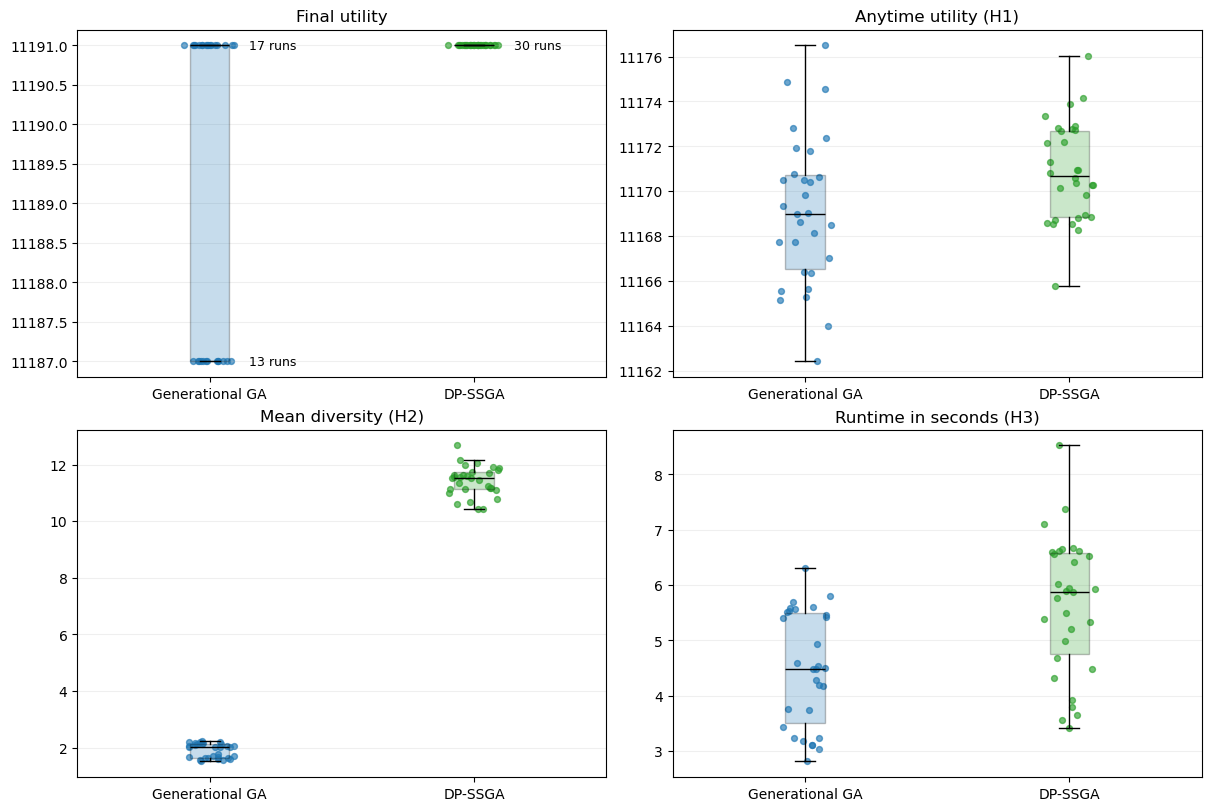

In [51]:
part3_plot_boxplots(part3_records)

The final-utility panel shows two outcomes for the Generational GA: 17 runs reach 11,191 and 13 stop at 11,187, while every DP-SSGA run reaches 11,191. The anytime boxes overlap, although DP-SSGA's median is higher. The diversity boxes do not overlap at all: every DP-SSGA run stays above 10 Hamming bits and every Generational GA run below 3. The runtime distributions overlap partly.

**3.4.11 Convergence and Diversity Curves**

In [52]:
def part3_curve_statistics(runs, variant, curve_name):
    """Return the median and interquartile range at each checkpoint."""
    curves = np.stack([run[curve_name] for run in runs[variant]])
    return np.median(curves, axis=0), np.percentile(curves, [25, 75], axis=0)


In [53]:
def part3_plot_progress(runs):
    """Show utility, a near-ceiling zoom, and diversity on log evaluation axes."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), constrained_layout=True)

    for variant in PART3_VARIANTS:
        color = PART3_COLORS[variant]
        utility_median, utility_iqr = part3_curve_statistics(runs, variant, "utility_curve")
        diversity_median, diversity_iqr = part3_curve_statistics(runs, variant, "diversity_curve")

        for axis in axes[:2]:
            axis.step(PART3_CHECKPOINTS, utility_median, where="post", color=color, label=variant)
            axis.fill_between(PART3_CHECKPOINTS, *utility_iqr, step="post", color=color, alpha=0.15)

        axes[2].plot(PART3_CHECKPOINTS, diversity_median, color=color, label=variant)
        axes[2].fill_between(PART3_CHECKPOINTS, *diversity_iqr, color=color, alpha=0.15)

    axes[0].set(title="Best-so-far utility: full range", ylabel="Utility")
    axes[1].set(title="Best-so-far utility: 99%-100%", ylabel="Utility")
    axes[1].set_ylim(0.99 * PART3_REFERENCE_UTILITY, PART3_REFERENCE_UTILITY)
    axes[2].set(title="Population diversity", ylabel="Mean pairwise Hamming distance")
    for axis in axes:
        axis.set_xscale("log")
        axis.set_xlim(50, 20_000)
        axis.set_xlabel("Fitness evaluations (log scale)")
        axis.grid(alpha=0.2)
    axes[0].legend(fontsize=8)
    plt.show()


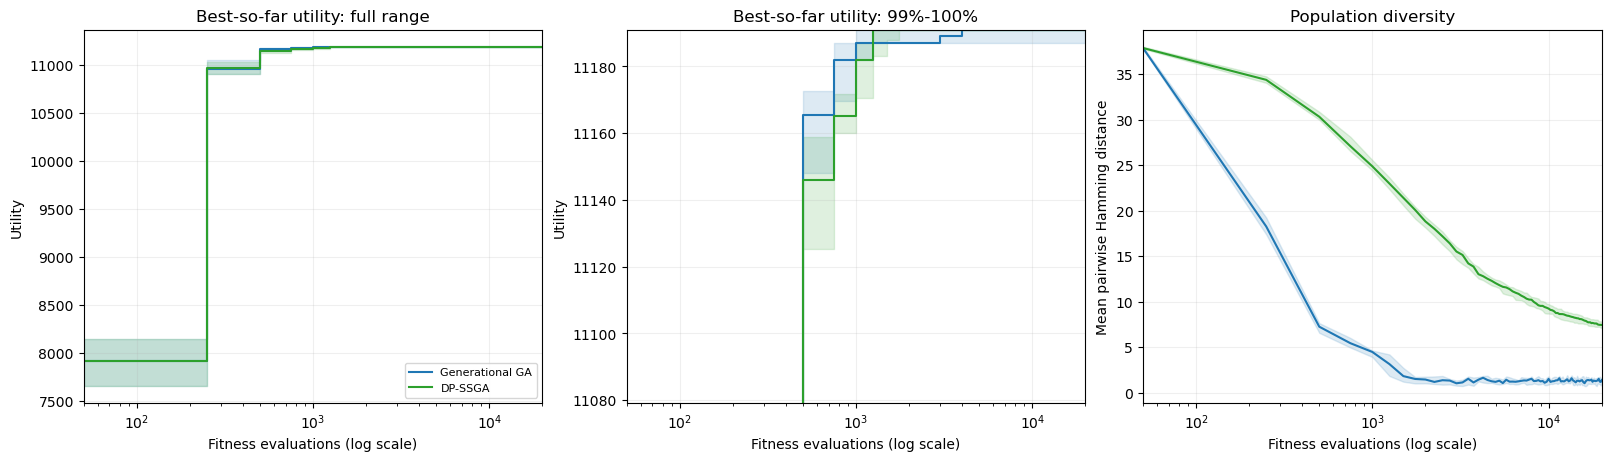

In [54]:
part3_plot_progress(part3_runs)

The full-range panel shows both variants gaining most of their utility within the first 1,000 evaluations. The near-ceiling panel shows a crossover: the Generational GA's median leads between about 500 and 1,000 evaluations, but DP-SSGA's median reaches 11,191 at about 1,250 evaluations, while the Generational GA's lower quartile stays at 11,187 until the end. This early lead explains why DP-SSGA's anytime advantage is small. The diversity panel shows the Generational GA losing almost all its diversity by about 2,000 evaluations, while DP-SSGA's diversity falls gradually and ends near 7.5 bits. Each line is the median of the runs, and its shaded band shows the interquartile range.

**3.4.12 Non-Parametric Hypothesis Testing**

I pair the runs by seed. For each seed, both GAs start from the same 50-chromosome population, because `np.random.seed(seed)` runs just before `initial_population()` in both runners. A paired test therefore removes the variation that comes from the starting population.

The Wilcoxon signed-rank test does not require the paired differences to follow a normal distribution (bell-curve shape), but it does assume that they are independent, which separate seeds give, and roughly symmetric around their median [5]. Because symmetry is not guaranteed, I add two checks: a sign test [6], which only counts how often DP-SSGA scores higher, and a bootstrap 95% confidence interval for each median difference (10,000 resamples of the 30 seeds).

I run one-sided Wilcoxon signed-rank tests [4], [5] on the paired differences (DP-SSGA − Generational GA), matching the direction each hypothesis predicts:

- **H1:** anytime utility;
- **H2:** mean diversity;
- **H3:** runtime.

Each test at the 5% level has a 5% chance of a false positive, so testing three hypotheses gives up to a 14% chance ($1 - 0.95^3$) that at least one result is a false positive [6]. Holm's method [6] keeps that family-wise chance at 5%. I apply it separately to the Wilcoxon and sign-test p-values. The first table below reports each median paired difference, its confidence interval and the number of seeds on which DP-SSGA scores higher; the second shows each Wilcoxon p-value's rank (`p_rank`; Holm multiplies the p-values ranked 1, 2 and 3 by 3, 2 and 1) and the Holm-adjusted values.

In [55]:
from scipy.stats import wilcoxon, binomtest

def holm(p_values):
    """Holm step-down adjustment [6], returned in the original order."""
    p = np.asarray(p_values, dtype=float)
    order = np.argsort(p)
    adjusted = np.minimum(1, np.maximum.accumulate(p[order] * (len(p) - np.arange(len(p)))))
    return adjusted[np.argsort(order)]

assert np.allclose(holm([0.01, 0.04, 0.03]), [0.03, 0.06, 0.06])

rng = np.random.default_rng(2026)  # own generator, so no other result changes
tests = [  # (hypothesis, metric): each predicts DP-SSGA > Generational GA
    ("H1", "anytime_utility"),
    ("H2", "mean_diversity"),
    ("H3", "runtime_s"),
]
rows = []
for hypothesis, metric in tests:
    # One row per seed, so each difference compares a matched pair of runs.
    by_seed = part3_records.pivot(index="seed", columns="variant", values=metric)
    diff = (by_seed["DP-SSGA"] - by_seed["Generational GA"]).to_numpy()
    boot = np.median(rng.choice(diff, size=(10_000, len(diff))), axis=1)  # bootstrap over seeds
    low, high = np.percentile(boot, [2.5, 97.5])
    wins, nonzero = int((diff > 0).sum()), int((diff != 0).sum())
    rows.append({
        "hypothesis": hypothesis,
        "metric": metric,
        "median_diff": np.median(diff),
        "ci_low": low,
        "ci_high": high,
        "dp_ssga_higher": f"{wins}/{len(diff)}",
        "p": wilcoxon(diff, alternative="greater").pvalue,
        "sign_p": binomtest(wins, nonzero, 0.5, alternative="greater").pvalue,
    })

part3_tests = pd.DataFrame(rows)
part3_tests["p_holm"] = holm(part3_tests["p"])
part3_tests["sign_p_holm"] = holm(part3_tests["sign_p"])
part3_tests["p_rank"] = part3_tests["p"].rank().astype(int)  # 1 = smallest; Holm multiplies by 3, 2, 1
fmt = lambda x: f"{x:.3g}"

print("Paired differences, DP-SSGA − Generational GA (95% CI from 10,000 bootstrap resamples of the seeds)")
print(part3_tests[["hypothesis", "metric", "median_diff", "ci_low", "ci_high", "dp_ssga_higher"]].to_string(index=False, float_format=fmt))
print()
print("One-sided Wilcoxon signed-rank and sign tests (each family Holm-adjusted across 3 tests)")
print(part3_tests[["hypothesis", "p", "p_rank", "p_holm", "sign_p", "sign_p_holm"]].to_string(index=False, float_format=fmt))


Paired differences, DP-SSGA − Generational GA (95% CI from 10,000 bootstrap resamples of the seeds)
hypothesis          metric  median_diff  ci_low  ci_high dp_ssga_higher
        H1 anytime_utility         1.52  -0.172     2.56          19/30
        H2  mean_diversity         9.51    9.37     9.63          30/30
        H3       runtime_s         1.11   0.855     1.51          27/30

One-sided Wilcoxon signed-rank and sign tests (each family Holm-adjusted across 3 tests)
hypothesis        p  p_rank   p_holm   sign_p  sign_p_holm
        H1  0.00773       3  0.00773      0.1          0.1
        H2 9.31e-10       1 2.79e-09 9.31e-10     2.79e-09
        H3 2.86e-07       2 5.72e-07 4.22e-06     8.43e-06


The Wilcoxon tests reject all three null hypotheses at the 5% level after Holm adjustment, and the robustness checks confirm H2 and H3 but not H1.

For H1, DP-SSGA's anytime utility is higher on 19 of 30 seeds, by a median of 1.52 ($p_{holm} = 7.73 \times 10^{-3}$). The sign test does not confirm this ($p_{holm} = 0.10$), and the 95% confidence interval for the median difference, [−0.17, 2.56], includes zero. Wilcoxon reaches significance because DP-SSGA's wins are larger than its losses, which depends on the symmetry assumption. H1 is therefore only weakly supported, consistent with the Generational GA's early lead (Section 3.4.11).

For H2, DP-SSGA keeps more diversity on all 30 seeds, with a median gain of 9.51 Hamming bits (95% CI [9.37, 9.63]; $p_{holm} = 2.79 \times 10^{-9}$), and the sign test agrees. For H3, DP-SSGA is slower on most seeds (H3 row of the table above), and both tests are significant after Holm adjustment.

Together, the results show a trade-off. DP-SSGA keeps about six times more diversity and reaches 11,191 in every run, while the Generational GA converges early and stalls at 11,187 in 13 runs. DP-SSGA pays for this with more runtime and more repair work per child.

**3.4.13 Critical Reflection**

**Statistical and practical significance.** The Wilcoxon tests reject all three null hypotheses, but the effects differ in size and robustness. In utility terms, the final gap is small: 4 points in 13 runs, under 0.04% of 11,191. The difference in reliability matters more. An engineer who runs the Generational GA once has a 13-in-30 chance of receiving the weaker configuration, while DP-SSGA returned 11,191 every time. The anytime lead is the weakest effect (1.76 points, higher on 19 of 30 seeds, and not confirmed by the sign test or the confidence interval), and the diversity effect is the largest (six times higher, with no overlap between runs).

**What causes the difference.** The two designs differ in two ways: when parents are updated, and which chromosome a child replaces. I therefore cannot credit the gain to Hamming crowding alone; a steady-state GA without crowding might reach 11,191 just as reliably. The diversity curves fit the reasoning behind H1. The Generational GA's diversity falls below 2 bits by about 2,000 evaluations, so crossover mostly recombines near-identical parents, and 13 runs stay at 11,187. This link is a correlation in my data, and I did not test it directly.

**Diversity costs repair work.** DP-SSGA children were infeasible before repair 48.9% of the time, against 34.9% for the Generational GA, and repair dropped 1.93 models per child against 1.19. Diverse parents produce children that mix more different selections, so more of them exceed capacity. This repair work, not only the Hamming comparisons I named in H3, probably adds to DP-SSGA's runtime, and my timing cannot separate the two.

**Limitations of the study.** All results come from one instance and one parameter setting (population 50, crossover 0.8, mutation $1/90$), and I did not tune either variant separately. The Generational GA uses one survival scheme, the old elite plus the best 49 children; a scheme that keeps more weak children might hold more diversity. I cannot claim 11,191 is optimal, because it is only the best utility I observed. Runtime is the weakest measure: wall-clock time depends on the machine and its load, and the run-to-run standard deviations in Section 3.4.9 are comparable to the gap between the means. Operation counts would give a more stable measure of cost.


## 4. References

[1] S. Luke, *Essentials of Metaheuristics*, 2nd ed. Lulu, 2013. [Online]. Available: https://people.cs.gmu.edu/~sean/book/metaheuristics/

[2] P. C. Chu and J. E. Beasley, "A Genetic Algorithm for the Multidimensional Knapsack Problem," Journal of Heuristics, vol. 4, no. 1, pp. 63–86, 1998. doi: https://doi.org/10.1023/A:1009642405419

[3] O. J. Mengshoel and D. E. Goldberg, "The Crowding Approach to Niching in Genetic Algorithms," Evolutionary Computation, vol. 16, no. 3, pp. 315–354, 2008. [Online]. Available: https://www.researchgate.net/publication/23276281_The_Crowding_Approach_to_Niching_in_Genetic_Algorithms

[4] F. Wilcoxon, "Individual Comparisons by Ranking Methods," Biometrics Bulletin, vol. 1, no. 6, 1945. doi: https://doi.org/10.2307/3001968

[5] The SciPy Community, "scipy.stats.wilcoxon," SciPy Reference Guide. [Online]. Available: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.wilcoxon.html

[6] J. Derrac, S. García, D. Molina, and F. Herrera, "A Practical Tutorial on the Use of Nonparametric Statistical Tests as a Methodology for Comparing Evolutionary and Swarm Intelligence Algorithms," Swarm and Evolutionary Computation, vol. 1, no. 1, pp. 3–18, 2011. doi: https://doi.org/10.1016/j.swevo.2011.02.002